# 10. Modelos numéricos y búsqueda de configuraciones

Se comparan redes densas (MLP), recurrentes (LSTM) y convolucionales temporales (CNN1D) para pronosticar el precio nacional horario de bolsa. La búsqueda comprende 192 configuraciones y 4800 ajustes, exclusivamente con desarrollo 2000–2021. El MAE en COP/kWh es la métrica principal del benchmark y el criterio de selección; RMSE y R² son métricas secundarias. Se utilizan cinco bloques de validación consecutivos en 2018–2021 y cinco inicializaciones por configuración. La justificación bibliográfica y la agregación se desarrollan en la [sección 8.2](08_validacion.ipynb).

El experimento utiliza únicamente variables numéricas y calendario. Los resultados presentados son de **selección en validación**: el mismo bloque interviene en la parada anticipada y en la comparación de configuraciones. Los resultados corresponden exclusivamente a desarrollo; no constituyen una evaluación externa ni un benchmark confirmatorio.

## 10.1 Estructura de la entrada y disponibilidad temporal

Para un origen diario $o$ a las 00:00 de Colombia y una longitud de historia $L$, una observación supervisada está formada por

$$
X_o=[\mathbf x_{o-L},\ldots,\mathbf x_{o-1}]\in\mathbb R^{L\times37},\qquad
\mathbf y_o=(y_o,\ldots,y_{o+23})\in\mathbb R^{24}.
$$

El eje temporal conserva frecuencia horaria; la salida predice directamente las 24 horas siguientes. No se realimentan predicciones entre horizontes.

| Bloque predictor | Variables | Columnas | Disponibilidad implementada |
|---|---|---:|---|
| Precio | Precio nacional de bolsa, COP/kWh | 1 | Desplazamiento de 24 horas |
| Demanda | Demanda real y comercial, kWh | 2 | Desplazamiento de 24 horas |
| Meteorología | Temperatura, humedad relativa y precipitación en ocho ciudades | 24 | Desplazamiento de 24 horas |
| Hidrología | Llenado, reserva útil, capacidad útil y aportes diarios | 4 | Dos días desde el inicio del día de referencia; último registro disponible |
| Calendario | Seno y coseno de los ciclos horario, semanal y anual | 6 | Calculados para la fecha de cada fila de entrada |
| **Total** | | **37** | |

Las ciudades son Bogotá, Medellín, Cali, Barranquilla, Cartagena, Bucaramanga, Pereira y Cúcuta. Para una variable horaria $v$, la fila alineada en $s$ contiene $v_{s-24}$. El dato horario más reciente de $X_o$ corresponde a $o-25$ horas; la hidrología se incorpora mediante una unión temporal hacia atrás según su fecha de disponibilidad. Estos rezagos son supuestos retrospectivos, no horarios de publicación certificados. Las variables climáticas proceden de reanálisis y las series pueden incorporar revisiones.

```{figure} _static/modelos-entrada.svg
:alt: Datos numéricos y calendario alineados, ventanas temporales, escalado y salida de 24 precios.
:width: 100%

Construcción de cada ejemplo supervisado. La historia varía entre 24 y 336 horas; las columnas predictoras y el horizonte permanecen constantes.
```

<!-- figure-interpretation:diagram_modelos-entrada:start -->
**Interpretación.** Las 37 variables se alinean según su disponibilidad y forman una ventana temporal que produce 24 precios horarios. La preparación compartida mantiene comparables las fuentes de información entre familias.
<!-- figure-interpretation:diagram_modelos-entrada:end -->


Las entradas se estandarizan por columna con media y desviación estimadas exclusivamente sobre las filas utilizadas por el entrenamiento del fold. El objetivo se divide por su desviación de entrenamiento $s_y>0$, sin centrarlo. Esta transformación permite imponer positividad en unidades originales:

$$
\widetilde y=y/s_y,\qquad
\widehat y=s_y\,\operatorname{Softplus}(z),\qquad
\operatorname{Softplus}(z)=\log(1+e^z).
$$

La restricción supone precios no negativos. Softplus produce valores estrictamente positivos y una derivada sigmoide; no representa exactamente cero. No se aplica sobre un objetivo centrado. La salida tiene 24 componentes porque el horizonte comprende 24 horas, no por una restricción de la arquitectura.

## 10.2 Configuración MLP seleccionada

La variante **M3**, con historia de **24 horas**, transforma $X_o\in\mathbb R^{24\times37}$ en un vector de 888 entradas. Utiliza dos capas ocultas de 256 y 128 unidades, activación ReLU, Dropout de 0,1 después de cada activación, y una proyección a 24 salidas con Softplus. La penalización seleccionada es $\lambda=10^{-3}$.

```{figure} _static/modelos-mlp.svg
:alt: Entrada 24 por 37, aplanamiento a 888, capas densas de 256 y 128, proyección a 24 y Softplus.
:width: 100%

MLP seleccionada. Las dimensiones representan una observación, sin el eje de lote.
```

<!-- figure-interpretation:diagram_modelos-mlp:start -->
**Interpretación.** La MLP convierte 24 × 37 entradas en un vector de 888 valores y utiliza capas de 256 y 128 unidades. Esta representación combina posiciones y variables mediante 263576 parámetros, el mayor tamaño de las tres configuraciones.
<!-- figure-interpretation:diagram_modelos-mlp:end -->


Con $\mathbf h^{(0)}=\operatorname{vec}(X_o)$, las capas ocultas calculan

$$
\mathbf h^{(\ell)}=D_{0.1}\!\left[\max(0,W_\ell\mathbf h^{(\ell-1)}+\mathbf b_\ell)\right],\qquad \ell\in\{1,2\}.
$$

La salida es $\widehat{\mathbf y}_o=s_y\operatorname{Softplus}(W_3\mathbf h^{(2)}+\mathbf b_3)$. Durante entrenamiento, $D_p(\mathbf h)=\mathbf m\odot\mathbf h/(1-p)$, con máscaras Bernoulli de probabilidad $1-p$; en evaluación actúa como identidad. Las matrices densas permiten interacciones no lineales entre variables y posiciones temporales. El aplanamiento conserva la posición mediante pesos específicos, pero no impone compartición temporal; su número de parámetros crece con $L$.

Esta estructura sigue los fundamentos de las [redes de propagación hacia delante de Goodfellow, Bengio y Courville](https://www.deeplearningbook.org/contents/mlp.html). Los tamaños concretos se seleccionaron dentro del espacio experimental declarado; no corresponden a una reproducción exacta de una arquitectura publicada.

## 10.3 Configuración LSTM seleccionada

La variante **L2** utiliza **72 horas**, una capa LSTM unidireccional de **64 unidades**, el último estado oculto, Dropout de 0,1 y una proyección de 64 a 24 con Softplus. La penalización seleccionada es $\lambda=10^{-3}$. Cada ventana inicia sus estados oculto y de celda en cero; no se transfiere estado entre ejemplos.

```{figure} _static/modelos-lstm.svg
:alt: Secuencia 72 por 37, LSTM de 64 unidades, último estado, Dropout, proyección a 24 y Softplus.
:width: 100%

LSTM seleccionada. La secuencia completa se procesa antes de emitir el horizonte diario.
```

<!-- figure-interpretation:diagram_modelos-lstm:start -->
**Interpretación.** La LSTM resume 72 horas en un estado de 64 unidades y genera las 24 salidas. Sus 27928 parámetros constituyen el menor tamaño del grupo, aunque esta configuración registra el mayor tiempo medio de ajuste.
<!-- figure-interpretation:diagram_modelos-lstm:end -->


Para el paso temporal $s$, la implementación combina la entrada $\mathbf x_s$, el estado oculto $\mathbf h_{s-1}$ y la memoria $\mathbf c_{s-1}$:

$$
\begin{aligned}
\mathbf i_s&=\sigma(W_{xi}\mathbf x_s+W_{hi}\mathbf h_{s-1}+\mathbf b_i),\\
\mathbf f_s&=\sigma(W_{xf}\mathbf x_s+W_{hf}\mathbf h_{s-1}+\mathbf b_f),\\
\mathbf g_s&=\tanh(W_{xg}\mathbf x_s+W_{hg}\mathbf h_{s-1}+\mathbf b_g),\\
\mathbf o_s&=\sigma(W_{xo}\mathbf x_s+W_{ho}\mathbf h_{s-1}+\mathbf b_o),\\
\mathbf c_s&=\mathbf f_s\odot\mathbf c_{s-1}+\mathbf i_s\odot\mathbf g_s,\\
\mathbf h_s&=\mathbf o_s\odot\tanh(\mathbf c_s).
\end{aligned}
$$

Las compuertas regulan conservación, incorporación y exposición de información. La actualización aditiva de la memoria favorece la propagación de gradientes respecto de una recurrencia puramente multiplicativa, sin garantizar que cualquier dependencia larga pueda aprenderse. La salida usa $\mathbf h_{o-1}$ para los 24 horizontes. Los fundamentos se remontan a [Hochreiter y Schmidhuber (1997)](https://www.bioinf.jku.at/publications/older/2604.pdf); las ecuaciones con compuerta de olvido y las convenciones implementadas corresponden a la [LSTM de PyTorch](https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html).

## 10.4 Configuración CNN1D seleccionada

La variante **C3** emplea **24 horas**, dos convoluciones temporales de **64 filtros**, kernel de longitud **5**, paso 1 y padding 2. Cada convolución se sigue de ReLU y Dropout1d de 0,1. Un promedio adaptativo reduce el eje temporal a siete posiciones; el tensor $64\times7$ se aplana a 448 componentes y se proyecta a 24 salidas con Softplus. La penalización seleccionada es $\lambda=10^{-4}$.

```{figure} _static/modelos-cnn.svg
:alt: Entrada 37 por 24, dos convoluciones de 64 filtros, pooling a siete posiciones, aplanamiento y salida positiva de 24 precios.
:width: 100%

CNN1D seleccionada. Se transpone la entrada para que los predictores formen el eje de canales.
```

<!-- figure-interpretation:diagram_modelos-cnn:start -->
**Interpretación.** Las dos convoluciones comparten filtros sobre 24 horas y el pooling resume la secuencia en siete posiciones antes de producir los 24 precios. La configuración utiliza 43224 parámetros y obtiene el menor MAE global entre los candidatos seleccionados.
<!-- figure-interpretation:diagram_modelos-cnn:end -->


Cada filtro combina los canales de entrada en un entorno temporal compartiendo parámetros entre posiciones. Con padding cero y kernel 5, una capa calcula la correlación cruzada

$$
z_{c,s}=b_c+\sum_{j=1}^{C_{\mathrm{in}}}\sum_{q=0}^{4}K_{c,j,q}\,h_{j,s+q-2},\qquad h'_{c,s}=\max(0,z_{c,s}).
$$

Las dos capas generan un campo receptivo local de nueve horas antes del pooling. El promedio adaptativo calcula siete promedios sobre intervalos del eje temporal; para 24 posiciones, los intervalos pueden solaparse por el redondeo de sus límites. La capa densa integra después esas representaciones a lo largo de toda la ventana. Dropout1d elimina canales completos durante entrenamiento. El padding simétrico utiliza posiciones de la ventana histórica; no incorpora datos posteriores al origen de pronóstico.

La compartición de filtros reduce la dependencia del número de parámetros respecto de la longitud de entrada y favorece la detección de patrones locales repetidos. El pooling reduce resolución temporal, por lo que puede perder detalle de la hora exacta. Véanse los fundamentos de [redes convolucionales](https://www.deeplearningbook.org/contents/convnets.html) y la [documentación de Conv1d](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv1d.html).

## 10.5 Espacio de búsqueda y protocolo de entrenamiento

La búsqueda exhaustiva cruza las siguientes doce arquitecturas con cuatro contextos y cuatro penalizaciones. El Dropout se mantiene en 0,1 en todos los candidatos.

| Familia | Código | Configuración estructural |
|---|---|---|
| MLP | M1 | Densas 64 → 32 |
| MLP | M2 | Densas 128 → 64 |
| MLP | M3 | Densas 256 → 128 |
| MLP | M4 | Densas 128 → 64 → 32 |
| LSTM | L1 | Una capa, 32 unidades |
| LSTM | L2 | Una capa, 64 unidades |
| LSTM | L3 | Dos capas, 32 unidades por capa |
| LSTM | L4 | Una capa de 64 unidades y densa intermedia de 32 |
| CNN1D | C1 | Dos convoluciones, 32 filtros, kernel 5 |
| CNN1D | C2 | Dos convoluciones, 32 filtros, kernel 3 |
| CNN1D | C3 | Dos convoluciones, 64 filtros, kernel 5 |
| CNN1D | C4 | Tres convoluciones, 32 filtros, kernel 3, dilataciones 1, 2 y 4 |

Los contextos son $L\in\{24,72,168,336\}$ horas y Ridge usa $\lambda\in\{0,10^{-5},10^{-4},10^{-3}\}$. El total es $12\times4\times4=192$ configuraciones, con cinco folds y cinco semillas (11037–11041), para **4800 ajustes desde cero**. No se descartan configuraciones según resultados intermedios. Los orígenes admisibles se fijan con la ventana máxima de 336 horas y se comparten entre todas las longitudes. Los cinco bloques consecutivos de validación cubren 2018–2021 y el entrenamiento se amplía antes de cada bloque.

La función objetivo es

$$
\mathcal L(\theta)=\frac{1}{24N}\sum_{i=1}^{N}\sum_{h=0}^{23}\left|\frac{y_{i,h}}{s_y}-\operatorname{Softplus}(z_{i,h})\right|
+\lambda\sum_{W\in\mathcal W}\lVert W\rVert_F^2.
$$

$\mathcal W$ comprende las matrices y tensores de pesos con más de una dimensión; se excluyen sesgos. La suma L2 no se normaliza por la cantidad de parámetros: un mismo $\lambda$ no supone igual regularización efectiva entre arquitecturas. Se utiliza Adam con tasa $10^{-3}$, `weight_decay=0`, lotes de 256 y recorte de la norma del gradiente a 1. Los gradientes se obtienen por retropropagación; en LSTM, a través de la secuencia temporal.

La parada anticipada monitoriza **MAE de validación en COP/kWh, sin penalización**. Una reducción relativa de al menos 0,2 % respecto de la referencia acumulada reinicia la paciencia. Se detiene después de 15 épocas sin esa mejora, con mínimo de 20 y máximo de 200 épocas. Se conservan los pesos de menor MAE absoluto, aunque esa época sea anterior a la 20. El umbral define una meseta práctica; no representa significancia estadística ni el margen de relevancia confirmatorio $\delta$.

Las familias representan hipótesis inductivas diferentes: interacciones densas por posición, memoria recurrente y patrones locales con pesos compartidos. La revisión de textos completos del [capítulo 9](09_literatura.ipynb) verifica LSTM en 7/16 estudios puntuales, MLP/DNN en 6/16 y CNN en 2/16. La selección combina recurrencia y simplicidad con memoria, interacciones por posición y patrones locales. CNN empata en frecuencia con CNN-LSTM y Transformer; su estructura convolucional independiente permite mantener tres referencias diferenciadas. Una referencia describe explícitamente CNN1D y otra no permite confirmar la dimensión. Los tamaños concretos se seleccionaron en desarrollo y constituyen adaptaciones, no réplicas exactas de esos artículos. El capítulo 9 presenta fuentes, configuraciones reportadas, análisis crítico y fórmulas de parámetros y costo. El mismo máximo de épocas no iguala costo computacional ni capacidad. El dimensionamiento y los contrastes de validación se presentan en las secciones 10.10–10.13; la evaluación de prueba se presenta en la sección 10.17.


### Preparación temporal y escalado: implementación

Las siguientes funciones construyen las entradas exclusivamente con desarrollo y conservan los controles de disponibilidad y separación temporal.

In [1]:
%matplotlib inline
from pathlib import Path

ROOT = next(
    directory for directory in [Path.cwd(), *Path.cwd().parents]
    if (directory / "data/manifest.json").exists()
)

from sklearn.preprocessing import StandardScaler
from IPython.display import Markdown, display
import datetime as dt
import hashlib
import json
import numpy as np
import pandas as pd
import re

In [2]:
TARGET = 'precio_bolsa_cop_kwh'
ALLOWED_SOURCES = {'El Tiempo', 'El Espectador', 'Semana', 'Portafolio', 'La República', 'El Colombiano', 'Dinero', 'IDEAM', 'XM'}
EDA_SPLITS = {'train': (2000, 2017), 'validation': (2018, 2021), 'test': (2022, 2025)}
SPLITS = EDA_SPLITS
TIME = 'timestamp_start_colombia'
RESULTS = ROOT / 'results'
WEATHER_PREFIXES = ('temperature_2m_c_', 'relative_humidity_2m_pct_', 'precipitation_preceding_hour_mm_')
CITIES = {'bogota', 'medellin', 'cali', 'barranquilla', 'cartagena', 'bucaramanga', 'pereira', 'cucuta'}
NUMERIC_E1 = {TARGET, 'demanda_real_kwh', 'demanda_comercial_kwh', 'llenado_valor_original', 'reserva_util_kwh', 'capacidad_util_kwh', 'aportes_kwh_dia'}
PIPELINE_DEFAULTS = {'method': 'split_train_val_forwardChaining', 'n_splits': 5, 'development_start': '2000-01-01T00:00:00-05:00', 'validation_start': '2018-01-01T00:00:00-05:00', 'development_end_exclusive': '2022-01-01T00:00:00-05:00', 'test_start': '2022-01-01T00:00:00-05:00', 'test_end_exclusive': '2026-01-01T00:00:00-05:00', 'lookback_hours': 168, 'horizon_hours': 24, 'stride_hours': 24, 'hourly_release_lag_hours': 24, 'hydrology_release_lag_days': 2, 'include_calendar': True, 'seed': 11037, 'availability_scenario': 'retrospective_assumed_release_lags'}
RESULTS.mkdir(exist_ok=True)
(RESULTS / 'figures').mkdir(exist_ok=True)
(RESULTS / 'tables').mkdir(exist_ok=True)
pd.set_option('display.max_rows', 35)
pd.set_option('display.max_columns', 14)
pd.set_option('display.float_format', lambda x: f'{x:.5g}')

In [3]:
def aware(value):
    parsed = dt.datetime.fromisoformat(value.replace('Z', '+00:00'))
    if parsed.tzinfo is None:
        raise ValueError('Timestamp must have an explicit timezone')
    return parsed

In [4]:
def eligible(record, origin):
    cutoff = aware(origin)
    if (record.get('source') or record.get('medium')) not in ALLOWED_SOURCES:
        return False
    if record.get('availability_status') != 'verified_archived_version':
        return False
    if record.get('availability_proof') != 'wayback_payload_digest_and_capture':
        return False
    clean_flag = record.get('quarantined', False) in (False, 0, None, '', '0', 'false', 'False')
    if not re.fullmatch('[0-9a-f]{64}', record.get('version_sha256') or '') or not clean_flag:
        return False
    available = record.get('available_at_verified')
    captured = record.get('capture_at_verified')
    if not available or not captured:
        return False
    return aware(captured) <= aware(available) <= cutoff

In [5]:
def split_train_val_forwardChaining(sequence, numInputs, numOutputs, numJumps):
    """ Returns sets to train and cross-validate a model using forward chaining technique
    
    Parameters:
        sequence (array)  : Full training dataset
        numInputs (int)   : Number of inputs X and Xcv used at each training and validation
        numOutputs (int)  : Number of outputs y and ycv used at each training and validation
        numJumps (int)    : Number of sequence samples to be ignored between (X,y) sets

    Returns:
        X (2D array)    : Array of numInputs arrays used for training
        y (2D array)    : Array of numOutputs arrays used for training
        Xcv (2D array)  : Array of numInputs arrays used for cross-validation
        ycv (2D array)  : Array of numOutputs arrays used for cross-validation
        
    

Fuente: timeseries-cv 0.1.5; licencia original:
MIT License

Copyright (c) 2021 DidierRLopes

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.

The MIT License (MIT)

Copyright (c) 2019 Didier Rodrigues Lopes

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.
"""
    X, y, Xcv, ycv = (dict(), dict(), dict(), dict())
    j = 2
    while 1:
        start_ix = 0
        end_ix = 0
        startCv_ix = 0
        endCv_ix = 0
        X_it, y_it, Xcv_it, ycv_it = (list(), list(), list(), list())
        i = 0
        while i < j:
            start_ix = numJumps * i
            end_ix = start_ix + numInputs
            seq_x = sequence[start_ix:end_ix]
            X_it.append(seq_x)
            seq_y = sequence[end_ix:end_ix + numOutputs]
            y_it.append(seq_y)
            i += 1
        if end_ix + numInputs + numOutputs > len(sequence):
            break
        startCv_ix = end_ix
        endCv_ix = end_ix + numInputs
        seq_xcv = sequence[startCv_ix:endCv_ix]
        Xcv_it.append(seq_xcv)
        seq_ycv = sequence[endCv_ix:endCv_ix + numOutputs]
        ycv_it.append(seq_ycv)
        X[j - 2] = np.array(X_it)
        y[j - 2] = np.array(y_it)
        Xcv[j - 2] = np.array(Xcv_it)
        ycv[j - 2] = np.array(ycv_it)
        j += 1
    if len(X) == 0 or len(Xcv) == 0:
        print('The sequence provided does not has size enough to populate the return arrays')
    return (X, y, Xcv, ycv)

In [6]:
def validate_development_index(index, config):
    index = pd.DatetimeIndex(index)
    if index.tz is None:
        raise ValueError('El índice debe tener zona horaria.')
    index = index.tz_convert('America/Bogota')
    if len(index) < 2 or not index.is_monotonic_increasing or index.has_duplicates:
        raise ValueError('Índice temporal desordenado, duplicado o insuficiente.')
    if not np.all(np.diff(index.as_unit('ns').asi8) == pd.Timedelta(hours=1).value):
        raise ValueError('El calendario horario contiene huecos.')
    if index[0] < pd.Timestamp(config['development_start']) or index[-1] >= pd.Timestamp(config['development_end_exclusive']):
        raise PermissionError('La preparación sólo admite el periodo de desarrollo.')
    return index

In [7]:
def forward_chaining_folds(index, config, input_usable=None, target_usable=None):
    """Plan temporal por bloques; ventanas supervisadas completas y sin etiquetas compartidas."""
    index = validate_development_index(index, config)
    length = len(index)
    lookback = config['lookback_hours']
    horizon = config['horizon_hours']
    origins = np.arange(lookback, length - horizon + 1, config['stride_hours'], dtype=np.int64)
    origins = origins[index[origins].hour == 0]
    if input_usable is not None:
        flags = np.asarray(input_usable, dtype=bool)
        if flags.shape != (length,):
            raise ValueError('Máscara de entradas incompatible')
        bad = np.r_[0, np.cumsum(~flags)]
        origins = origins[bad[origins] - bad[origins - lookback] == 0]
    if target_usable is not None:
        flags = np.asarray(target_usable, dtype=bool)
        if flags.shape != (length,):
            raise ValueError('Máscara de etiquetas incompatible')
        bad = np.r_[0, np.cumsum(~flags)]
        origins = origins[bad[origins + horizon] - bad[origins] == 0]
    initial = origins[index[origins] < pd.Timestamp(config['validation_start'])]
    eligible = origins[index[origins] >= pd.Timestamp(config['validation_start'])]
    if len(initial) < 3 or len(eligible) < config['n_splits']:
        raise ValueError('Datos insuficientes para los folds.')
    validation_blocks = np.array_split(eligible, config['n_splits'])
    train_x, train_y, val_x, val_y = split_train_val_forwardChaining(np.arange(config['n_splits'] + 3), 1, 1, 1)
    if len(val_y) != config['n_splits']:
        raise AssertionError('Número inesperado de folds del backend')
    folds = []
    for key in sorted(val_y):
        block = int(val_y[key].ravel()[0])
        block_id = block - 3
        past_blocks = np.unique(np.r_[train_x[key].ravel(), train_y[key].ravel()])
        if past_blocks.max() >= block:
            raise AssertionError('El backend incluyó bloques futuros')
        start = int(validation_blocks[block_id][0])
        stop = int(validation_blocks[block_id + 1][0]) if block_id + 1 < len(validation_blocks) else length
        train = origins[origins + horizon <= start]
        validation = validation_blocks[block_id]
        validation = validation[validation + horizon <= stop]
        if not len(train) or not len(validation):
            raise ValueError('Fold vacío tras la purga de etiquetas')
        assert train[-1] + horizon <= validation[0]
        digest = hashlib.sha256(train.astype('<i8').tobytes() + validation.astype('<i8').tobytes()).hexdigest()
        folds.append(dict(fold=len(folds) + 1, train_origins=train, validation_origins=validation, validation_block=block, indices_sha256=digest))
    return folds

In [8]:
def table(frame, name):
    frame.to_csv(RESULTS / 'tables' / (name + '.csv'), index=True)
    display(frame)
    return None

In [9]:
def load_numeric(split='train', table='hourly', *, allow_test=False):
    if split not in SPLITS:
        raise ValueError('Unknown split')
    if split == 'test' and (not allow_test):
        raise PermissionError('El EDA no puede consultar valores de prueba.')
    a, b = SPLITS[split]
    folder = 'hourly' if table == 'hourly' else 'hydrology'
    frame = pd.concat([pd.read_csv(ROOT / f'data/numeric/{folder}/{year}.csv.gz') for year in range(a, b + 1)], ignore_index=True)
    if table == 'hourly':
        frame.index = pd.DatetimeIndex(pd.to_datetime(frame[TIME], utc=True)).tz_convert('America/Bogota')
    else:
        frame.index = pd.DatetimeIndex(pd.to_datetime(frame['date'])).tz_localize('America/Bogota')
    frame.index.name = 'tiempo_colombia'
    return frame

In [10]:
def load_development_data(table='hourly'):
    return pd.concat([load_numeric('train', table=table), load_numeric('validation', table=table)]).sort_index()

In [11]:
def assert_e1_features(names):
    for name in names:
        if name in NUMERIC_E1:
            continue
        if any((name == prefix + city for prefix in WEATHER_PREFIXES for city in CITIES)):
            continue
        if name in {'hour_sin', 'hour_cos', 'week_sin', 'week_cos', 'year_sin', 'year_cos'}:
            continue
        raise ValueError('E1 sólo admite las variables numéricas declaradas: ' + name)
    return True

In [12]:
def numeric_feature_frame(hourly, hydrology, config):
    index = validate_development_index(hourly.index, config)
    if not hydrology.index.is_monotonic_increasing or hydrology.index.has_duplicates:
        raise ValueError('Índice hidrológico no válido.')
    if hydrology.index.tz is None or (len(hydrology) and hydrology.index[-1] >= pd.Timestamp(config['development_end_exclusive'])):
        raise PermissionError('Hidrología fuera del periodo de desarrollo o sin zona horaria.')
    columns = [TARGET, 'demanda_real_kwh', 'demanda_comercial_kwh']
    columns += sorted((c for c in hourly.columns if c.startswith(WEATHER_PREFIXES)))
    features = hourly[columns].shift(config['hourly_release_lag_hours']).copy()
    hydro_columns = ['llenado_valor_original', 'reserva_util_kwh', 'capacidad_util_kwh', 'aportes_kwh_dia']
    released = hydrology[hydro_columns].copy()
    released.index = released.index + pd.Timedelta(days=config['hydrology_release_lag_days'])
    features = features.join(released.reindex(index, method='ffill'))
    if config['include_calendar']:
        phases = {'hour': index.hour / 24, 'week': (index.day_of_week + index.hour / 24) / 7, 'year': (index.day_of_year - 1 + index.hour / 24) / np.where(index.is_leap_year, 366, 365)}
        for name, phase in phases.items():
            features[name + '_sin'] = np.sin(2 * np.pi * phase)
            features[name + '_cos'] = np.cos(2 * np.pi * phase)
    assert_e1_features(features.columns)
    return features

In [13]:
def pipeline_config(overrides=None):
    config = dict(PIPELINE_DEFAULTS)
    if overrides:
        unknown = set(overrides) - set(config)
        if unknown:
            raise ValueError('Opciones desconocidas: ' + str(sorted(unknown)))
        config.update(overrides)
    for field in ['n_splits', 'lookback_hours', 'horizon_hours', 'stride_hours']:
        if not isinstance(config[field], int) or isinstance(config[field], bool) or config[field] < 1:
            raise ValueError('Se requiere un entero positivo: ' + field)
    for field in ['hourly_release_lag_hours', 'hydrology_release_lag_days']:
        if not isinstance(config[field], int) or isinstance(config[field], bool) or config[field] < 0:
            raise ValueError('Rezago inválido: ' + field)
    if config['hydrology_release_lag_days'] < 1:
        raise ValueError('La hidrología diaria requiere al menos el cierre del día.')
    for field in ['development_start', 'validation_start', 'development_end_exclusive', 'test_start', 'test_end_exclusive']:
        if pd.Timestamp(config[field]).tzinfo is None:
            raise ValueError('Se requiere zona horaria: ' + field)
    if config['method'] != 'split_train_val_forwardChaining':
        raise ValueError('Método no autorizado')
    if pd.Timestamp(config['test_start']) != pd.Timestamp(PIPELINE_DEFAULTS['test_start']) or config['test_end_exclusive'] != PIPELINE_DEFAULTS['test_end_exclusive']:
        raise ValueError('El periodo de prueba está congelado.')
    if not pd.Timestamp(config['development_start']) < pd.Timestamp(config['validation_start']) < pd.Timestamp(config['development_end_exclusive']) <= pd.Timestamp(config['test_start']):
        raise ValueError('Cortes temporales inválidos')
    if config['stride_hours'] % 24:
        raise ValueError('Los orígenes deben conservar el paso diario.')
    return config

In [14]:
def build_training_pipeline(config=None, hourly=None, hydrology=None):
    config = pipeline_config(config)
    hourly = load_development_data() if hourly is None else hourly
    hydrology = load_development_data('hydrology') if hydrology is None else hydrology
    features = numeric_feature_frame(hourly, hydrology, config)
    target = hourly[TARGET].copy()
    usable = np.isfinite(features.to_numpy()).all(axis=1)
    folds = forward_chaining_folds(features.index, config, usable, np.isfinite(target.to_numpy()))
    return dict(config=config, features=features, target=target, folds=folds)

In [15]:
def load_pipeline_config(path=None):
    path = ROOT / 'configs/training_pipeline.json' if path is None else path
    return pipeline_config(json.loads(path.read_text(encoding='utf-8')))

In [16]:
def prepare_fold_arrays(pipeline, fold):
    features = pipeline['features']
    target = pipeline['target'].to_numpy()
    config = pipeline['config']
    lookback = config['lookback_hours']
    horizon = config['horizon_hours']
    train = fold['train_origins']
    validation = fold['validation_origins']
    train_positions = train[:, None] - lookback + np.arange(lookback)
    validation_positions = validation[:, None] - lookback + np.arange(lookback)
    train_rows = np.unique(train_positions)
    validation_rows = np.unique(validation_positions)
    scaler = StandardScaler().fit(features.iloc[train_rows])
    scaled_train = scaler.transform(features.iloc[train_rows]).astype(np.float32)
    scaled_validation = scaler.transform(features.iloc[validation_rows]).astype(np.float32)
    X_train = scaled_train[np.searchsorted(train_rows, train_positions)]
    X_validation = scaled_validation[np.searchsorted(validation_rows, validation_positions)]
    y_train = target[train[:, None] + np.arange(horizon)].astype(np.float32)
    y_validation = target[validation[:, None] + np.arange(horizon)].astype(np.float32)
    assert features.index[train_rows[-1]] < features.index[validation[0]]
    return dict(fold=fold['fold'], X_train=X_train, y_train=y_train, X_validation=X_validation, y_validation=y_validation, feature_scaler=scaler, feature_names=list(features.columns), train_origins=features.index[train], validation_origins=features.index[validation], scaler_fit_rows=len(train_rows), scaler_fit_start=features.index[train_rows[0]], scaler_fit_end=features.index[train_rows[-1]], target_units='COP/kWh')

## 10.6 Resultados y referencia estacional

Para cada semilla se concatenan los errores de todos los orígenes y las 24 horas de los cinco folds. Se calcula MAE, RMSE y R² sobre esa concatenación; después se promedian las cinco métricas. La desviación estándar refleja variación entre inicializaciones, no incertidumbre temporal. El RMSE se obtiene de errores cuadrados agrupados, no promediando directamente los RMSE de folds.

La referencia estacional repite el precio observado 168 horas antes de cada hora objetivo: $\widehat y^{\mathrm{sem}}_{o+h}=y_{o+h-168}$. Se evalúa sobre los mismos orígenes. La mejora porcentual es $100(1-\operatorname{MAE}_{\mathrm{modelo}}/\operatorname{MAE}_{\mathrm{sem}})$; esta razón no se denomina MASE.


In [17]:
import json
import numpy as np
import pandas as pd
from IPython.display import display
from io import BytesIO
from zipfile import ZipFile
RESULTS = ROOT / 'results/variant_search'
metrics = pd.read_csv(RESULTS / 'metrics.csv')
summary = pd.read_csv(RESULTS / 'summary.csv')
winners = pd.read_csv(RESULTS / 'best_by_family.csv')
assert len(metrics) == 4800 and len(summary) == 192
assert not metrics.duplicated(['candidate', 'fold', 'seed']).any()
assert json.loads((RESULTS / 'completed.json').read_text())['test_evaluated'] is False
pipeline = build_training_pipeline(dict(load_pipeline_config(), lookback_hours=336))
y_all, weekly_all = [], []
for fold in pipeline['folds']:
    positions = fold['validation_origins'][:, None] + np.arange(24)
    y_all.append(pipeline['target'].to_numpy()[positions])
    weekly_all.append(pipeline['target'].to_numpy()[positions - 168])
y_all, weekly_all = np.concatenate(y_all), np.concatenate(weekly_all)
error = weekly_all - y_all
baseline = {'mae': float(np.abs(error).mean()),
            'rmse': float(np.sqrt(np.square(error).mean())),
            'r2': float(1 - np.square(error).sum() / np.square(y_all - y_all.mean()).sum())}
records = [{'Modelo': 'Referencia semanal', 'Configuración': 'Repetición a 168 h',
            'MAE': baseline['mae'], 'DE MAE': np.nan, 'RMSE': baseline['rmse'],
            'R²': baseline['r2'], 'Reducción MAE (%)': 0.0}]
prediction_archive = ZipFile(RESULTS / 'selected_predictions.zip')
for row in winners.itertuples():
    # R² se verifica desde las predicciones de cada semilla, sin abrir prueba.
    r2_values = []
    for seed in range(11037, 11042):
        actual, predicted = [], []
        for fold in range(1, 6):
            folder = RESULTS / 'runs' / row.candidate / f'fold_{fold}_seed_{seed}'
            archive_path = f'{row.candidate}/fold_{fold}_seed_{seed}/predictions.npz'
            with np.load(BytesIO(prediction_archive.read(archive_path))) as saved:
                yy = saved['actual'].astype(np.float64).ravel()
                pp = saved['predictions'].astype(np.float64).ravel()
                actual.append(yy); predicted.append(pp)
        yy, pp = np.concatenate(actual), np.concatenate(predicted)
        r2_values.append(1 - np.square(yy-pp).sum() / np.square(yy-yy.mean()).sum())
    assert np.isclose(np.mean(r2_values), row.r2)
    records.append({'Modelo': row.family, 'Configuración': row.candidate,
                    'MAE': row.mae, 'DE MAE': row.mae_sd, 'RMSE': row.rmse,
                    'R²': row.r2, 'Reducción MAE (%)': 100*(1-row.mae/baseline['mae'])})
prediction_archive.close()
comparison = pd.DataFrame(records)
display(comparison.style.format({'MAE':'{:.3f}', 'DE MAE':'{:.3f}', 'RMSE':'{:.3f}',
                                 'R²':'{:.4f}', 'Reducción MAE (%)':'{:.2f}'}, na_rep='—').hide(axis='index'))


Modelo,Configuración,MAE,DE MAE,RMSE,R²,Reducción MAE (%)
Referencia semanal,Repetición a 168 h,40.157,—,62.444,0.6596,0.00
CNN1D,C3_h24_l2_0.0001,24.155,0.144,37.604,0.8766,39.85
LSTM,L2_h72_l2_0.001,24.624,0.101,37.773,0.8755,38.68
MLP,M3_h24_l2_0.001,24.992,0.095,37.953,0.8743,37.76


### Capacidad y comportamiento de la parada

Las épocas óptimas pueden preceder al mínimo de 20: ese mínimo restringe cuándo se detiene el ajuste, no qué checkpoint se conserva. Los conteos incluyen pesos y sesgos entrenables.

In [18]:
rows = []
for w in winners.itertuples():
    g = metrics[metrics.candidate == w.candidate]
    rows.append({'Modelo':w.family, 'Parámetros':int(g.parameters.iloc[0]),
                 'Mejor época (mediana)':g.best_epoch.median(),
                 'Época de parada (mediana)':g.epochs.median(),
                 'Ajustes':len(g)})
display(pd.DataFrame(rows).style.format(precision=0).hide(axis='index'))
assert (metrics.stop_reason == 'patience').all()
display(pd.DataFrame([{'Ajustes completos':len(metrics), 'Configuraciones':len(summary),
                       'Épocas promedio':metrics.epochs.mean(), 'Máximo observado':metrics.epochs.max(),
                       'Duración (horas)':json.loads((RESULTS/'completed.json').read_text())['total_seconds']/3600}]).style.format(precision=2).hide(axis='index'))

Modelo,Parámetros,Mejor época (mediana),Época de parada (mediana),Ajustes
CNN1D,43224,23,38,25
LSTM,27928,22,36,25
MLP,263576,18,33,25


Ajustes completos,Configuraciones,Épocas promedio,Máximo observado,Duración (horas)
4800,192,35.98,125,11.33


### Comparación con la referencia semanal

Las barras muestran el MAE agrupado y las líneas de error, la desviación estándar entre semillas; no representan intervalos de confianza temporal.

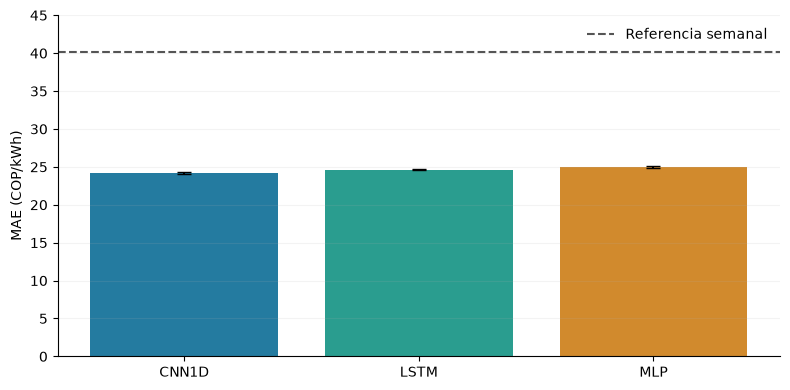

In [19]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4))
positions = np.arange(len(winners))
ax.bar(positions, winners.mae, yerr=winners.mae_sd, capsize=5,
       color=['#247ba0','#2a9d8f','#d18a2d'])
ax.axhline(baseline['mae'], color='#555555', linestyle='--', label='Referencia semanal')
ax.set_xticks(positions, winners.family)
ax.set_ylabel('MAE (COP/kWh)'); ax.set_ylim(0, 45)
ax.legend(frameon=False); ax.spines[['top','right']].set_visible(False)
ax.grid(axis='y', alpha=.15); fig.tight_layout(); plt.show()

**Interpretación.** CNN1D obtiene el menor MAE medio (24,155 COP/kWh), seguida de LSTM (24,624) y MLP (24,992). Las diferencias entre redes son menores que la ventaja frente a la referencia semanal (40,157); las barras de error describen variación entre semillas.

La configuración C3 con 24 horas de historia y $\lambda=10^{-4}$ presenta el menor MAE medio de selección. La reducción respecto de la referencia semanal es cercana al 40 %. Las diferencias entre familias se analizan mediante bloques temporales y corrección por comparaciones múltiples en las secciones 10.12–10.13.

Los contextos de 24 y 72 horas concentran las mejores configuraciones por familia. Esto no demuestra ausencia de información útil en historias más largas: capacidad, regularización, optimización y representación temporal se modifican conjuntamente. La positividad de salida y el procedimiento de parada también difieren del piloto inicial de 30 épocas, por lo que el cambio de error no puede atribuirse a un único factor.

Los 4800 ajustes terminaron por paciencia y ninguno alcanzó el máximo de 200 épocas. Las curvas ilustrativas permiten examinar mejoras iniciales y estabilización, pero el umbral del 0,2 % no es un contraste de hipótesis. El uso de validación tanto para elegir la época como para seleccionar entre 192 candidatos introduce optimismo. Estos valores no deben presentarse como errores de prueba de los nuevos modelos.

## 10.7 Alcance de la evaluación

La búsqueda utiliza datos retrospectivos y rezagos de disponibilidad supuestos. Las variables meteorológicas urbanas no representan directamente las cuencas aportantes; la correlación entre predictores dificulta atribuir su contribución individual. El análisis de importancia de los modelos iniciales no se transfiere automáticamente a estas nuevas configuraciones.

La validación utilizada para selección no constituye una estimación externa imparcial. El protocolo de las secciones 8.3–8.4 fija δ = 2 % de reducción relativa del MAE, α = 0,05, potencia objetivo ≥ 0,80 y tres comparaciones con ajuste de Holm. La unidad de evaluación es el origen diario de 24 precios; la incertidumbre temporal se estima con bloques móviles de 14 días, manteniendo separada la inicialización. El dimensionamiento y los contrastes de validación se presentan en las secciones siguientes. La evaluación temporal de prueba de las arquitecturas congeladas se presenta en la sección 10.17.

## 10.8 Código del pipeline de entrenamiento

Las celdas siguientes contienen las definiciones ejecutables de las arquitecturas, penalización, parada y búsqueda utilizadas. Las funciones de preparación temporal y escalado aparecen al inicio del cuaderno. La ejecución documental define las funciones y verifica los artefactos, sin repetir los 4800 ajustes. El entrenamiento completo se invoca desde la raíz del repositorio mediante `python scripts/train_variants.py --device auto`. La ejecución admite CPU o una GPU CUDA/ROCm compatible con la instalación de PyTorch; `--device cpu` fuerza CPU y `--device gpu` exige GPU. El registro identifica el dispositivo utilizado.


In [20]:
SOURCE_PATH = ROOT / 'scripts/train_variants.py'

In [21]:
%matplotlib inline
from pathlib import Path

ROOT = next(
    directory for directory in [Path.cwd(), *Path.cwd().parents]
    if (directory / "data/manifest.json").exists()
)

from pathlib import Path
from contextlib import contextmanager
import numpy as np
import os
import platform
import random
import sys
import torch

In [22]:
@contextmanager
def exclusive_run(path):
    """Bloqueo no bloqueante, liberado incluso si la ejecución falla."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    stream = path.open('a+b')
    locked = False
    try:
        stream.seek(0, 2)
        if stream.tell() == 0:
            stream.write(b'0')
            stream.flush()
        stream.seek(0)
        try:
            if os.name == 'nt':
                import msvcrt
                msvcrt.locking(stream.fileno(), msvcrt.LK_NBLCK, 1)
            else:
                import fcntl
                fcntl.flock(stream.fileno(), fcntl.LOCK_EX | fcntl.LOCK_NB)
            locked = True
        except OSError as exc:
            raise RuntimeError(f'Ya hay una ejecución activa para {path.parent}.') from exc
        yield
    finally:
        if locked:
            stream.seek(0)
            if os.name == 'nt':
                import msvcrt
                msvcrt.locking(stream.fileno(), msvcrt.LK_UNLCK, 1)
            else:
                import fcntl
                fcntl.flock(stream.fileno(), fcntl.LOCK_UN)
        stream.close()

In [23]:
def runtime_environment(device, threads):
    device = torch.device(device)
    environment = dict(platform=platform.platform(), os_name=os.name, python=sys.version, torch=torch.__version__, numpy=np.__version__, device=str(device), threads=threads, cuda=torch.version.cuda, hip=torch.version.hip, cpu=platform.processor(), deterministic_algorithms=torch.are_deterministic_algorithms_enabled(), hip_override=os.environ.get('HSA_OVERRIDE_GFX_VERSION'))
    environment['backend'] = ('rocm' if torch.version.hip else 'cuda') if device.type == 'cuda' else 'cpu'
    if device.type == 'cuda':
        environment.update(gpu=torch.cuda.get_device_name(device), gpu_memory_bytes=torch.cuda.get_device_properties(device).total_memory)
    return environment

In [24]:
def seed_training(seed, device):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.device(device).type == 'cuda':
        torch.cuda.manual_seed_all(seed)

In [25]:
def select_device(requested='auto'):
    """Auto usa CUDA/ROCm si está disponible; CPU en caso contrario."""
    requested = requested.lower()
    if requested == 'cpu':
        return torch.device('cpu')
    if requested in ('auto', 'gpu'):
        if torch.cuda.is_available():
            return torch.device('cuda:0')
        if requested == 'auto':
            return torch.device('cpu')
        raise RuntimeError('GPU solicitada pero PyTorch no detecta CUDA/ROCm. Use --device cpu o instale una distribución compatible.')
    try:
        device = torch.device(requested)
    except (RuntimeError, ValueError) as exc:
        raise ValueError('Dispositivo válido: auto, cpu, gpu, cuda o cuda:N.') from exc
    if device.type != 'cuda':
        raise ValueError('Dispositivo válido: auto, cpu, gpu, cuda o cuda:N.')
    if not torch.cuda.is_available():
        raise RuntimeError('CUDA/ROCm no disponible; use --device cpu.')
    index = 0 if device.index is None else device.index
    if index < 0 or index >= torch.cuda.device_count():
        raise ValueError(f'Índice GPU fuera de rango: {index}.')
    return torch.device(f'cuda:{index}')

In [26]:
def synchronize_device(device):
    if torch.device(device).type == 'cuda':
        torch.cuda.synchronize(device)

In [27]:
import argparse, copy, hashlib, html, itertools, json, os, random, sys, time

In [28]:
from pathlib import Path

In [29]:
import numpy as np

In [30]:
import pandas as pd

In [31]:
import torch

In [32]:
from torch import nn

In [33]:
ARCHITECTURES = {'M1': dict(family='MLP', widths=[64, 32]), 'M2': dict(family='MLP', widths=[128, 64]), 'M3': dict(family='MLP', widths=[256, 128]), 'M4': dict(family='MLP', widths=[128, 64, 32]), 'L1': dict(family='LSTM', hidden=32, layers=1, dense=False), 'L2': dict(family='LSTM', hidden=64, layers=1, dense=False), 'L3': dict(family='LSTM', hidden=32, layers=2, dense=False), 'L4': dict(family='LSTM', hidden=64, layers=1, dense=True), 'C1': dict(family='CNN1D', channels=32, kernel=5, dilations=[1, 1]), 'C2': dict(family='CNN1D', channels=32, kernel=3, dilations=[1, 1]), 'C3': dict(family='CNN1D', channels=64, kernel=5, dilations=[1, 1]), 'C4': dict(family='CNN1D', channels=32, kernel=3, dilations=[1, 2, 4])}

In [34]:
class Variant(nn.Module):

    def __init__(self, architecture, lookback, n_features, dropout=0.1):
        super().__init__()
        a = ARCHITECTURES[architecture]
        self.family = a['family']
        if self.family == 'MLP':
            layers = [nn.Flatten()]
            previous = lookback * n_features
            for width in a['widths']:
                layers += [nn.Linear(previous, width), nn.ReLU(), nn.Dropout(dropout)]
                previous = width
            self.net = nn.Sequential(*layers, nn.Linear(previous, 24))
        elif self.family == 'LSTM':
            self.net = nn.LSTM(n_features, a['hidden'], num_layers=a['layers'], batch_first=True, dropout=dropout if a['layers'] > 1 else 0.0)
            layers = [nn.Dropout(dropout)]
            if a['dense']:
                layers += [nn.Linear(a['hidden'], 32), nn.ReLU(), nn.Dropout(dropout)]
            self.head = nn.Sequential(*layers, nn.Linear(32 if a['dense'] else a['hidden'], 24))
        else:
            layers = []
            previous = n_features
            for dilation in a['dilations']:
                layers += [nn.Conv1d(previous, a['channels'], a['kernel'], dilation=dilation, padding=dilation * (a['kernel'] - 1) // 2), nn.ReLU(), nn.Dropout1d(dropout)]
                previous = a['channels']
            self.net = nn.Sequential(*layers, nn.AdaptiveAvgPool1d(7), nn.Flatten(), nn.Linear(previous * 7, 24))
        self.positive = nn.Softplus()

    def forward(self, x):
        if self.family == 'LSTM':
            sequence, _ = self.net(x)
            z = self.head(sequence[:, -1])
        else:
            z = self.net(x.transpose(1, 2) if self.family == 'CNN1D' else x)
        return self.positive(z)

In [35]:
def ridge_penalty(model):
    return sum((p.square().sum() for p in model.parameters() if p.ndim > 1))

In [36]:
class EarlyStop:

    def __init__(self, relative=0.002, patience=15, min_epochs=20):
        self.relative = relative
        self.patience = patience
        self.min_epochs = min_epochs
        self.reference = float('inf')
        self.best = float('inf')
        self.best_epoch = 0
        self.stale = 0

    def update(self, value, epoch):
        best = value < self.best
        if best:
            self.best = value
            self.best_epoch = epoch
        if value < self.reference * (1 - self.relative):
            self.reference = value
            self.stale = 0
        else:
            self.stale += 1
        return (best, epoch >= self.min_epochs and self.stale >= self.patience)

In [37]:
def atomic_json(path, data):
    tmp = path.with_suffix('.tmp')
    tmp.write_text(json.dumps(data, indent=2, allow_nan=False), encoding='utf-8')
    tmp.replace(path)

In [38]:
def publish(out, status):
    status['updated_at'] = pd.Timestamp.now(tz='America/Bogota').isoformat()
    atomic_json(out / 'status.json', status)
    done = status['completed']
    total = status['total']
    percent = 100 * done / total
    current = status.get('current', {})
    description = ' · '.join((f'{k}: {v}' for k, v in current.items()))
    page = f'''<!doctype html><html lang="es"><meta charset="utf-8"><meta name="viewport" content="width=device-width"><meta http-equiv="refresh" content="5"><title>Entrenamiento E1</title><style>body{{font:18px system-ui;background:#101820;color:#edf3f5;max-width:900px;margin:60px auto;padding:24px}}progress{{width:100%;height:34px;accent-color:#39c99a}}p{{line-height:1.6}}small{{color:#acbac4}}code{{overflow-wrap:anywhere}}h1{{font-size:28px}}</style><h1>Entrenamiento de variantes E1</h1><p>{html.escape(status['state'])}</p><progress value="{done}" max="{total}"></progress><p><strong>{done:,} / {total:,} ajustes · {percent:.2f}%</strong></p><p>{html.escape(description)}</p><p>Dropout 0,1 · 192 configuraciones · 5 folds · 5 semillas<br>Parada: MAE de validación, mejora 0,2%, paciencia 15, mínimo 20, máximo 200 épocas.<br>Salida positiva Softplus · Ridge explícito · Sin consultar prueba.</p><small>Actualización: {html.escape(status['updated_at'])} · Refresco cada 5 segundos</small></html>'''
    tmp = out / 'progress.tmp'
    tmp.write_text(page, encoding='utf-8')
    tmp.replace(out / 'progress.html')

In [39]:
def search_config():
    return dict(architectures=ARCHITECTURES, lookbacks=[24, 72, 168, 336], ridge=[0.0, 1e-05, 0.0001, 0.001], dropout=0.1, seeds=list(range(11037, 11042)), n_folds=5, max_epochs=200, min_epochs=20, patience=15, relative_improvement=0.002, batch_size=256, lr=0.001, weight_decay=0.0, target='price / train standard deviation, no centering', output='Softplus', pipeline=load_pipeline_config(), protocol_sha256=hashlib.sha256((ROOT / 'PROTOCOLO_VARIANTES_2026-11-05.md').read_bytes()).hexdigest(), source_sha256=hashlib.sha256(SOURCE_PATH.read_bytes()).hexdigest(), runtime_sha256=hashlib.sha256((ROOT / 'src/colombia_energy/runtime.py').read_bytes()).hexdigest())

In [40]:
def main():
    parser = argparse.ArgumentParser()
    parser.add_argument('--output', default='results/variant_search_portable')
    parser.add_argument('--device', default='auto', help='auto, cpu, gpu, cuda o cuda:N')
    parser.add_argument('--threads', type=int, default=4)
    args = parser.parse_args()
    if args.threads < 1:
        parser.error('--threads debe ser positivo')
    device = select_device(args.device)
    torch.set_num_threads(args.threads)
    out = ROOT / args.output
    out.mkdir(parents=True, exist_ok=True)
    with exclusive_run(out / 'runner.lock'):
        run_search(args, out, device)

In [41]:
def run_search(args, out, device):
    config = search_config()
    config['runtime'] = runtime_environment(device, args.threads)
    if (out / 'configuration.json').exists() and json.loads((out / 'configuration.json').read_text(encoding='utf-8')) != config:
        raise RuntimeError('Configuración/fuentes modificadas: usar otra carpeta')
    atomic_json(out / 'configuration.json', config)
    total = 12 * 4 * 4 * 5 * 5
    rows = [json.loads(p.read_text(encoding='utf-8')) for p in sorted(out.glob('runs/*/*/metrics.json'))]
    done = len(rows)
    started = time.time()
    status = dict(state='Preparando datos', completed=done, total=total, pid=os.getpid(), started_at=pd.Timestamp.now(tz='America/Bogota').isoformat())
    publish(out, status)
    try:
        atomic_json(out / 'environment.json', config['runtime'])
        print(json.dumps(config['runtime']), flush=True)
        base = build_training_pipeline(dict(config['pipeline'], lookback_hours=336))
        manifest = []
        for lookback in config['lookbacks']:
            pipeline = dict(base, config=dict(base['config'], lookback_hours=lookback))
            for fold in base['folds']:
                batch = prepare_fold_arrays(pipeline, fold)
                scaler = batch['feature_scaler']
                audit = dict(lookback=lookback, fold=batch['fold'], n_train=len(batch['y_train']), n_validation=len(batch['y_validation']), train_origins_sha256=hashlib.sha256(batch['train_origins'].asi8.tobytes()).hexdigest(), validation_origins_sha256=hashlib.sha256(batch['validation_origins'].asi8.tobytes()).hexdigest(), feature_names=batch['feature_names'], feature_mean=scaler.mean_.tolist(), feature_scale=scaler.scale_.tolist(), scaler_fit_start=str(batch['scaler_fit_start']), scaler_fit_end=str(batch['scaler_fit_end']), validation_start=str(batch['validation_origins'][0]), validation_last_origin=str(batch['validation_origins'][-1]))
                assert batch['train_origins'][-1] + pd.Timedelta(hours=24) <= batch['validation_origins'][0]
                assert batch['validation_origins'][-1] < pd.Timestamp(config['pipeline']['test_start'])
                prep = out / 'preprocessing'
                prep.mkdir(exist_ok=True)
                atomic_json(prep / f"context_{lookback}_fold_{fold['fold']}.json", audit)
                manifest.append(audit)
                atomic_json(out / 'fold_audit.json', manifest)
                scale = float(batch['y_train'].std())
                assert scale > 0 and np.all(batch['y_train'] >= 0)
                x = torch.as_tensor(batch['X_train'], device=device)
                y = torch.as_tensor(batch['y_train'] / scale, device=device)
                xv = torch.as_tensor(batch['X_validation'], device=device)
                yv = torch.as_tensor(batch['y_validation'], device=device)
                for architecture, ridge, seed in itertools.product(ARCHITECTURES, config['ridge'], config['seeds']):
                    candidate = f'{architecture}_h{lookback}_l2_{ridge:g}'
                    run = out / 'runs' / candidate / f"fold_{fold['fold']}_seed_{seed}"
                    if (run / 'metrics.json').exists():
                        continue
                    run.mkdir(parents=True, exist_ok=True)
                    seed_training(seed, device)
                    model = Variant(architecture, lookback, x.shape[-1], config['dropout']).to(device)
                    optimizer = torch.optim.Adam(model.parameters(), lr=config['lr'], weight_decay=0.0)
                    stopper = EarlyStop()
                    curves = []
                    best_state = None
                    synchronize_device(device)
                    t0 = time.perf_counter()
                    for epoch in range(1, 201):
                        model.train()
                        train_mae = 0.0
                        train_l2 = 0.0
                        for ix in torch.randperm(len(x), device=device).split(256):
                            optimizer.zero_grad(set_to_none=True)
                            mae = nn.functional.l1_loss(model(x[ix]), y[ix])
                            l2 = ridge_penalty(model)
                            loss = mae + ridge * l2
                            if not torch.isfinite(loss):
                                raise FloatingPointError(f'Pérdida no finita {candidate}')
                            loss.backward()
                            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                            optimizer.step()
                            train_mae += float(mae.detach()) * len(ix)
                            train_l2 += float(l2.detach()) * len(ix)
                        model.eval()
                        with torch.no_grad():
                            pred = torch.cat([model(z) for z in xv.split(256)]) * scale
                        val = float((pred - yv).abs().mean())
                        if not np.isfinite(val):
                            raise FloatingPointError('Validación no finita')
                        improved, stop = stopper.update(val, epoch)
                        if improved:
                            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                        curves.append(dict(epoch=epoch, train_mae_cop_kwh=train_mae / len(x) * scale, train_ridge_unweighted=train_l2 / len(x), validation_mae_cop_kwh=val))
                        status.update(state='Entrenando', completed=done, current=dict(configuration=candidate, fold=fold['fold'], seed=seed, epoch=epoch, best_epoch=stopper.best_epoch, best_mae=round(stopper.best, 4), epochs_without_relevant_gain=stopper.stale))
                        publish(out, status)
                        if epoch % 5 == 0 or stop:
                            pd.DataFrame(curves).to_csv(run / 'curves.csv', index=False)
                        if stop:
                            break
                    model.load_state_dict(best_state)
                    model.eval()
                    with torch.no_grad():
                        prediction = (torch.cat([model(z) for z in xv.split(256)]) * scale).cpu().numpy()
                    actual = batch['y_validation']
                    error = prediction.astype(np.float64) - actual
                    assert np.isfinite(prediction).all() and (prediction >= 0).all()
                    assert np.isclose(np.abs(error).mean(), stopper.best, rtol=1e-05, atol=0.001)
                    torch.save(dict(state_dict=best_state, architecture=architecture, lookback=lookback, dropout=0.1, ridge=ridge, seed=seed, fold=fold['fold'], target_scale=scale, n_features=x.shape[-1], best_epoch=stopper.best_epoch, preprocessing=audit, output='Softplus'), run / 'checkpoint.pt')
                    np.savez_compressed(run / 'predictions.npz', predictions=prediction, actual=actual, origins_ns=batch['validation_origins'].asi8, timezone='America/Bogota')
                    pd.DataFrame(curves).to_csv(run / 'curves.csv', index=False)
                    synchronize_device(device)
                    metrics = dict(candidate=candidate, architecture=architecture, family=ARCHITECTURES[architecture]['family'], lookback=lookback, ridge=ridge, seed=seed, fold=fold['fold'], epochs=epoch, best_epoch=stopper.best_epoch, mae=float(np.abs(error).mean()), rmse=float(np.sqrt(np.square(error).mean())), n_values=int(error.size), parameters=sum((p.numel() for p in model.parameters())), seconds=time.perf_counter() - t0, stop_reason='patience' if stop else 'max_epochs')
                    atomic_json(run / 'metrics.json', metrics)
                    rows.append(metrics)
                    done += 1
                    pd.DataFrame(rows).to_csv(out / 'metrics.csv', index=False)
                    status.update(completed=done)
                    publish(out, status)
                    print(f"{done}/{total} {candidate} fold={fold['fold']} seed={seed} best={stopper.best_epoch} stop={epoch} MAE={metrics['mae']:.4f}", flush=True)
                    del model, optimizer, pred, prediction, best_state
                del x, y, xv, yv, batch
        frame = pd.DataFrame(rows)
        aggregates = []
        for (candidate, seed), g in frame.groupby(['candidate', 'seed']):
            aggregates.append(dict(candidate=candidate, seed=int(seed), mae=float(np.average(g.mae, weights=g.n_values)), rmse=float(np.sqrt(np.average(g.rmse ** 2, weights=g.n_values)))))
        seeds = pd.DataFrame(aggregates)
        seeds.to_csv(out / 'metrics_per_seed.csv', index=False)
        summary = seeds.groupby('candidate').agg(mae=('mae', 'mean'), mae_sd=('mae', 'std'), rmse=('rmse', 'mean')).sort_values('mae')
        summary.to_csv(out / 'summary.csv')
        status.update(state='Completado', completed=done, current={})
        publish(out, status)
        atomic_json(out / 'completed.json', dict(runs=done, total_seconds=time.time() - started, test_evaluated=False))
    except BaseException as error:
        status.update(state='Error', error=str(error))
        publish(out, status)
        raise

### Reproducción y trazabilidad

Las fuentes originales del experimento se conservan con sus huellas en `resources/experiment_sources/`; el registro es `PROTOCOLO_VARIANTES_2026-11-05.md`. La versión portable de ejecución está en `scripts/train_variants.py`; los resultados están en `results/variant_search/`. La configuración histórica registra huellas del código original archivado y del protocolo original, localizable en Git mediante `resources/protocol_history.json`; cada checkpoint incluye arquitectura, contexto, penalización, semilla, escaladores y época óptima. La ejecución documental verifica resultados existentes y no inicia entrenamiento.

PyTorch 2.9.1+rocm6.4, Python 3.12.3 y AMD Radeon RX 6700 XT de 12 GB constituyen el entorno experimental. La ejecución empleó el ajuste de compatibilidad local `HSA_OVERRIDE_GFX_VERSION=10.3.0`; no se presupone necesario para otros dispositivos. La reconstrucción documental se realiza por CPU en Windows y Linux; no requiere los controladores de ese equipo ni repite los ajustes. Las nuevas ejecuciones usan una carpeta distinta y registran su entorno; los resultados entre dispositivos pueden diferir por aritmética y algoritmos de cálculo. Los datos y supuestos retrospectivos se describen en los capítulos de fuentes y validación.

## 10.9 Diagnóstico e inferencia de las predicciones disponibles

Se analizan 75 predicciones de validación con orígenes y etiquetas comunes. La incertidumbre temporal se estima por bloques móviles; la variación de inicialización se presenta por separado. Las especificaciones se conservan en `PROTOCOLO_ANALISIS_RESULTADOS_2026-11-06.md`. Los resultados corresponden a las configuraciones seleccionadas en estos mismos bloques.

In [42]:
import hashlib

In [43]:
import json

In [44]:
from io import BytesIO

In [45]:
from itertools import combinations

In [46]:
from pathlib import Path

In [47]:
from zipfile import ZipFile

In [48]:
import numpy as np

In [49]:
import pandas as pd

In [50]:
from scipy import stats

In [51]:
from scipy.integrate import quad

In [52]:
from scipy.optimize import brentq

In [53]:
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

In [54]:
from statsmodels.stats.multitest import multipletests

In [55]:
from statsmodels.tsa.stattools import bds, acf

In [56]:
BMK_FAMILIES = ['MLP', 'LSTM', 'CNN1D']

In [57]:
BMK_REFERENCES = ['Semanal', 'Persistencia disponible', 'Repetición 48 h']

In [58]:
def bmk_holm(values):
    values = np.asarray(values, dtype=float)
    adjusted = np.full(values.shape, np.nan)
    ok = np.isfinite(values)
    if ok.any():
        adjusted[ok] = multipletests(values[ok], method='holm')[1]
    return adjusted

In [59]:
def bmk_block_counts(folds, dates_ns, length, replicates, seed):
    """MBB estratificado; ningún bloque atraviesa un fold o hueco."""
    folds, dates_ns = (np.asarray(folds), np.asarray(dates_ns))
    if length < 1 or replicates < 1 or len(folds) != len(dates_ns):
        raise ValueError('Dimensiones o longitud de bloque inválidas.')
    rng = np.random.default_rng(seed)
    counts = np.zeros((replicates, len(folds)), dtype=np.int16)
    day = 24 * 3600 * 10 ** 9
    for fold in np.unique(folds):
        pos = np.flatnonzero(folds == fold)
        starts = [j for j in range(len(pos) - length + 1) if np.all(np.diff(dates_ns[pos[j:j + length]]) == day)]
        if not starts:
            raise ValueError('No hay bloques consecutivos suficientes.')
        sampled = rng.choice(starts, size=(replicates, int(np.ceil(len(pos) / length))))
        idx = pos[(sampled[:, :, None] + np.arange(length)).reshape(replicates, -1)[:, :len(pos)]]
        np.add.at(counts, (np.arange(replicates)[:, None], idx), 1)
        assert np.all(counts[:, pos].sum(axis=1) == len(pos))
    return counts

In [60]:
def bmk_training_scale(target, train_origins, season=168, horizon=24):
    used = np.zeros(len(target), dtype=bool)
    used[(np.asarray(train_origins)[:, None] + np.arange(horizon)).ravel()] = True
    positions = np.flatnonzero(used)
    positions = positions[positions >= season]
    positions = positions[used[positions - season]]
    scale = float(np.abs(np.asarray(target)[positions] - np.asarray(target)[positions - season]).mean())
    if not np.isfinite(scale) or scale <= 0:
        raise ValueError('Escala MASE no positiva o no finita.')
    return scale

In [61]:
def bmk_dm_hln(difference, folds, lag=13, effective_horizon=1):
    """DM con HAC Bartlett dentro de fold; HLN en unidades de origen diario."""
    d = np.asarray(difference, dtype=float)
    folds = np.asarray(folds)
    n = len(d)
    variance = 0.0
    for fold in np.unique(folds):
        z = d[folds == fold]
        z = z - z.mean()
        bandwidth = min(lag, len(z) - 1)
        long_run = np.dot(z, z) / len(z)
        for j in range(1, bandwidth + 1):
            long_run += 2 * (1 - j / (bandwidth + 1)) * np.dot(z[j:], z[:-j]) / len(z)
        variance += len(z) * max(float(long_run), 0.0) / n ** 2
    if variance <= np.finfo(float).eps:
        return (0.0, 1.0, 0.0) if np.allclose(d, 0) else (np.nan, np.nan, variance)
    factor = np.sqrt((n + 1 - 2 * effective_horizon + effective_horizon * (effective_horizon - 1) / n) / n)
    statistic = d.mean() / np.sqrt(variance) * factor
    pvalue = 2 * stats.t.sf(abs(statistic), n - 1)
    return (float(statistic), float(pvalue), float(variance))

In [62]:
def bmk_relative_tost(observed, bootstrap, delta):
    centered = np.asarray(bootstrap) - observed
    denominator = len(centered) + 1
    lower = (1 + np.count_nonzero(centered >= observed + delta)) / denominator
    upper = (1 + np.count_nonzero(centered <= observed - delta)) / denominator
    return float(max(lower, upper))

In [63]:
def bmk_t_power(effect, n, alpha):
    """Potencia t bilateral; integración de respaldo para colas nct no finitas."""
    df = n - 1
    critical = stats.t.isf(alpha / 2, df)
    noncentrality = abs(effect) * np.sqrt(n)
    value = stats.nct.sf(critical, df, noncentrality) + stats.nct.cdf(-critical, df, noncentrality)
    if not np.isfinite(value):

        def integrand(v):
            threshold = critical * np.sqrt(v / df)
            return (stats.norm.cdf(noncentrality - threshold) + stats.norm.cdf(-noncentrality - threshold)) * stats.chi2.pdf(v, df)
        value = quad(integrand, 0, np.inf, epsabs=1e-10, limit=150)[0]
    return float(np.clip(value, 0, 1))

In [64]:
def bmk_required_seeds(effect, alpha, target=0.8):
    if bmk_t_power(effect, 2, alpha) >= target:
        return 2
    upper = 8
    while bmk_t_power(effect, upper, alpha) < target:
        upper *= 2
        if upper > 1000000:
            raise ValueError('Dimensionamiento fuera del intervalo numérico.')
    return int(np.ceil(brentq(lambda n: bmk_t_power(effect, n, alpha) - target, 2, upper)))

In [65]:
def bmk_power_table(frame, source, delta=0.02, alpha=0.05 / 3):
    pivot = frame.pivot(index='seed', columns='family', values='mae').reindex(columns=BMK_FAMILIES)
    assert not pivot.isna().any().any() and len(pivot) >= 3
    variation, pairs = ([], [])
    for family in BMK_FAMILIES:
        x = pivot[family].to_numpy()
        variation.append(dict(fuente=source, modelo=family, semillas=len(x), MAE=x.mean(), DE=x.std(ddof=1), CV_pct=100 * x.std(ddof=1) / x.mean()))
    for a, b in combinations(BMK_FAMILIES, 2):
        x, y = (pivot[a].to_numpy(), pivot[b].to_numpy())
        d = x - y
        sigma = d.std(ddof=1)
        if not np.isfinite(sigma) or sigma <= 0:
            raise ValueError('Variabilidad pareada insuficiente para dimensionar.')
        margin = delta * x.mean()
        effect = margin / sigma
        required = bmk_required_seeds(effect, alpha)
        upper = 1.0
        while bmk_t_power(upper, len(d), alpha) < 0.8:
            upper *= 2
        mde_effect = brentq(lambda e: bmk_t_power(e, len(d), alpha) - 0.8, 0, upper)
        t = stats.ttest_rel(x, y)
        w = stats.wilcoxon(d, method='exact')
        ci = stats.t.ppf(0.975, len(d) - 1) * sigma / np.sqrt(len(d))
        pairs.append(dict(fuente=source, referencia=a, candidato=b, pares=len(d), diferencia=d.mean(), sigma_d=sigma, delta_COP_kWh=margin, delta_sobre_sigma=effect, R_normal_aprox=max(2, int(np.ceil(((stats.norm.ppf(1 - alpha / 2) + stats.norm.ppf(0.8)) * sigma / margin) ** 2))), R_t_pareada=max(2, required), MDE_COP_kWh=mde_effect * sigma, potencia_para_delta=bmk_t_power(effect, len(d), alpha), shapiro_p=stats.shapiro(d).pvalue, t_p=t.pvalue, wilcoxon_p=w.pvalue, IC95_t_inferior=d.mean() - ci, IC95_t_superior=d.mean() + ci, d_z=d.mean() / sigma))
    table = pd.DataFrame(pairs)
    table['t_p_Holm'] = bmk_holm(table.t_p)
    table['wilcoxon_p_Holm'] = bmk_holm(table.wilcoxon_p)
    return (pd.DataFrame(variation), table)

In [66]:
def bmk_load_existing(root, pipeline):
    folder = root / 'results/variant_search'
    winners = pd.read_csv(folder / 'best_by_family.csv').set_index('family').loc[BMK_FAMILIES]
    manifest = json.loads((folder / 'selected_predictions_manifest.json').read_text(encoding='utf-8'))
    hashes = {x['path']: x['sha256'] for x in manifest}
    target = pipeline['target'].to_numpy(dtype=float)
    index = pipeline['target'].index
    features = pipeline['features']
    seeds = list(range(11037, 11042))
    predictions = [[] for _ in BMK_FAMILIES]
    actual, origins, fold_ids, scales, regimes, price_groups, thresholds = ([], [], [], [], [], [], [])
    verified = 0
    with ZipFile(folder / 'selected_predictions.zip') as archive:
        for fold in pipeline['folds']:
            o = fold['validation_origins']
            times = index[o].as_unit('ns').asi8
            expected = target[o[:, None] + np.arange(24)]
            train = (fold['train_origins'][:, None] + np.arange(24)).ravel()
            assert train.max() < o.min()
            scale = bmk_training_scale(target, fold['train_origins'])
            low, high = np.quantile(target[train], [0.1, 0.9])
            train_fill = features.llenado_valor_original.iloc[fold['train_origins'] - 1].to_numpy()
            q1, q2 = np.quantile(train_fill, [1 / 3, 2 / 3])
            fill = features.llenado_valor_original.iloc[o - 1].to_numpy()
            regimes.extend(np.where(fill < q1, 'Bajo', np.where(fill > q2, 'Alto', 'Medio')))
            price_groups.append(np.where(expected < low, 'Bajo', np.where(expected > high, 'Alto', 'Central')))
            scales.extend([scale] * len(o))
            origins.extend(o)
            fold_ids.extend([fold['fold']] * len(o))
            thresholds.append(dict(fold=fold['fold'], horas_etiqueta_entrenamiento=len(np.unique(train)), MASE_escala=scale, precio_p10_train=low, precio_p90_train=high, llenado_q33_train=q1, llenado_q67_train=q2))
            reference_actual = None
            for m, family in enumerate(BMK_FAMILIES):
                per_seed = []
                for seed in seeds:
                    name = f"{winners.loc[family, 'candidate']}/fold_{fold['fold']}_seed_{seed}/predictions.npz"
                    data = archive.read(name)
                    if hashlib.sha256(data).hexdigest() != hashes[name]:
                        raise ValueError('La huella de una predicción no coincide.')
                    with np.load(BytesIO(data), allow_pickle=False) as saved:
                        assert np.array_equal(saved['origins_ns'], times)
                        yy = saved['actual'].astype(float)
                        assert yy.shape == (len(o), 24)
                        np.testing.assert_allclose(yy, expected, rtol=1e-06, atol=0.0001)
                        if reference_actual is None:
                            reference_actual = yy
                        else:
                            np.testing.assert_array_equal(yy, reference_actual)
                        pp = saved['predictions'].astype(float)
                        assert pp.shape == yy.shape and np.isfinite(pp).all()
                        per_seed.append(pp)
                    verified += 1
                predictions[m].append(np.stack(per_seed))
            actual.append(reference_actual)
    actual = np.concatenate(actual)
    origins = np.asarray(origins, dtype=int)
    fold_ids = np.asarray(fold_ids, dtype=int)
    assert len(np.unique(origins)) == len(origins) and index[origins].max() < pd.Timestamp('2022-01-01', tz='America/Bogota')
    model = np.stack([np.concatenate(x, axis=1) for x in predictions])
    references = [target[origins[:, None] + np.arange(24) - 168], np.repeat(target[origins - 25, None], 24, axis=1), target[origins[:, None] + np.arange(24) - 48]]
    model = np.concatenate([model, np.repeat(np.stack(references)[:, None], len(seeds), axis=1)])
    return dict(names=BMK_FAMILIES + BMK_REFERENCES, predictions=model, actual=actual, error=model - actual[None, None], origins=origins, dates=index[origins], fold_ids=fold_ids, scales=np.asarray(scales), regimes=np.asarray(regimes), price_groups=np.concatenate(price_groups), thresholds=pd.DataFrame(thresholds), verified_predictions=verified, winners=winners, seeds=seeds)

In [67]:
def bmk_residual_tests(data):
    rows = []
    error = data['error'][:3].mean(axis=-1)
    for m, family in enumerate(BMK_FAMILIES):
        for j, seed in enumerate(data['seeds']):
            for fold in np.unique(data['fold_ids']):
                e = error[m, j, data['fold_ids'] == fold]
                lb = acorr_ljungbox(e, lags=[7, 14, 28], model_df=0, return_df=True)
                for lag, r in lb.iterrows():
                    rows.append(dict(modelo=family, semilla=seed, fold=int(fold), prueba='Ljung–Box', parametro=int(lag), n=len(e), estadistico=r.lb_stat, p=r.lb_pvalue))
                lm = het_arch(e, nlags=7, ddof=0)
                rows.append(dict(modelo=family, semilla=seed, fold=int(fold), prueba='ARCH-LM', parametro=7, n=len(e), estadistico=lm[0], p=lm[1]))
                sample = e[-200:]
                z, p = bds(sample, max_dim=3, distance=1.5)
                for dimension, zz, pp in zip([2, 3], np.atleast_1d(z), np.atleast_1d(p)):
                    rows.append(dict(modelo=family, semilla=seed, fold=int(fold), prueba='BDS', parametro=dimension, n=len(sample), estadistico=zz, p=pp))
    frame = pd.DataFrame(rows)
    frame['p_Holm'] = np.nan
    for test in frame.prueba.unique():
        mask = frame.prueba == test
        frame.loc[mask, 'p_Holm'] = bmk_holm(frame.loc[mask, 'p'])
    return frame

In [68]:
def bmk_run(root, pipeline):
    root = Path(root)
    out = root / 'results/benchmark'
    out.mkdir(exist_ok=True)
    settings = json.loads((root / 'configs/benchmark_protocol.json').read_text(encoding='utf-8'))
    data = bmk_load_existing(root, pipeline)
    error = data['error']
    actual = data['actual']
    folds = data['fold_ids']
    n = len(actual)
    absolute = np.abs(error)
    squared = error ** 2
    daily = absolute.mean(axis=-1).mean(axis=1).T
    daily_squared = squared.mean(axis=-1)
    names = data['names']
    tables = {}
    per_seed = []
    for m, name in enumerate(names):
        for j, seed in enumerate(data['seeds']):
            per_seed.append(dict(family=name, seed=seed, mae=absolute[m, j].mean(), rmse=np.sqrt(squared[m, j].mean()), r2=1 - squared[m, j].sum() / np.square(actual - actual.mean()).sum(), mase=(absolute[m, j] / data['scales'][:, None]).mean(), sesgo=error[m, j].mean()))
    per_seed = pd.DataFrame(per_seed)
    tables['metricas_semilla'] = per_seed
    for family in BMK_FAMILIES:
        saved = data['winners'].loc[family]
        got = per_seed[per_seed.family == family]
        np.testing.assert_allclose(got.mae.mean(), saved.mae, rtol=1e-08)
        np.testing.assert_allclose(got.rmse.mean(), saved.rmse, rtol=1e-08)
    tables['umbrales_entrenamiento'] = data['thresholds']
    pilot = pd.read_csv(root / 'results/pilot_pytorch_gfx1030/metrics_per_seed.csv')
    pv, pp = bmk_power_table(pilot, 'Piloto')
    sv, sp = bmk_power_table(per_seed[per_seed.family.isin(BMK_FAMILIES)], 'Seleccionados')
    tables['variabilidad_semillas'] = pd.concat([pv, sv], ignore_index=True)
    tables['potencia_semillas'] = pd.concat([pp, sp], ignore_index=True)
    boot_primary = None
    comparison_rows = []
    metric_rows = []
    pair_indices = [(names.index(a), names.index(b)) for a, b in settings['comparisons']]
    for length in [14, 7, 28]:
        counts = bmk_block_counts(folds, data['dates'].as_unit('ns').asi8, length, settings['temporal_resampling']['replicates'], settings['temporal_resampling']['seed'])
        weights = counts.astype(float) / n
        boot = weights @ daily
        if length == 14:
            boot_primary = boot
            for m, name in enumerate(names):
                ss = weights @ daily_squared[m].T
                rmse = np.sqrt(ss).mean(axis=1)
                ymean = weights @ actual.mean(axis=1)
                ysecond = weights @ np.square(actual).mean(axis=1)
                r2 = 1 - ss.mean(axis=1) / (ysecond - ymean ** 2)
                mase = weights @ (absolute[m].mean(axis=(0, 2)) / data['scales'])
                rec = dict(modelo=name)
                means = per_seed[per_seed.family == name].mean(numeric_only=True)
                for label, replicates in [('mae', boot[:, m]), ('rmse', rmse), ('r2', r2), ('mase', mase)]:
                    rec[label] = means[label]
                    rec[label + '_IC95_inf'], rec[label + '_IC95_sup'] = np.quantile(replicates, [0.025, 0.975])
                rec['DE_semillas'] = per_seed[per_seed.family == name].mae.std(ddof=1)
                rec['sesgo'] = means.sesgo
                metric_rows.append(rec)
        for a, b in pair_indices:
            obs = daily[:, a].mean() - daily[:, b].mean()
            bs = boot[:, a] - boot[:, b]
            centered = bs - obs
            g = 1 - daily[:, b].mean() / daily[:, a].mean()
            bg = 1 - boot[:, b] / boot[:, a]
            row = dict(bloque_dias=length, referencia=names[a], candidato=names[b], diferencia_COP_kWh=obs, reduccion_pct=100 * g, SE_temporal=bs.std(ddof=1), p_bootstrap=(1 + np.count_nonzero(np.abs(centered) >= abs(obs))) / (len(bs) + 1), p_TOST=bmk_relative_tost(g, bg, 0.02), d_z_diario=obs / (daily[:, a] - daily[:, b]).std(ddof=1))
            row['IC95_inf'], row['IC95_sup'] = np.quantile(bs, [0.025, 0.975])
            d = daily[:, a] - daily[:, b]
            boot_sd = np.sqrt(np.maximum(weights @ np.square(d) - np.square(bs), 0))
            dz = np.divide(bs, boot_sd, out=np.full_like(bs, np.nan), where=boot_sd > 0)
            row['d_z_IC95_inf'], row['d_z_IC95_sup'] = np.nanquantile(dz, [0.025, 0.975])
            row['IC_sim_inf'], row['IC_sim_sup'] = np.quantile(bs, [0.05 / 6, 1 - 0.05 / 6])
            row['reduccion_IC_sim_inf_pct'], row['reduccion_IC_sim_sup_pct'] = 100 * np.quantile(bg, [0.05 / 6, 1 - 0.05 / 6])
            row['delta_COP_kWh'] = 0.02 * daily[:, a].mean()
            row['MDE_temporal_COP_kWh'] = (stats.norm.ppf(1 - 0.05 / 6) + stats.norm.ppf(0.8)) * row['SE_temporal']
            effect = row['delta_COP_kWh'] / row['SE_temporal']
            z = stats.norm.ppf(1 - 0.05 / 6)
            row['potencia_temporal_aprox_delta'] = stats.norm.cdf(-z - effect) + stats.norm.sf(z - effect)
            comparison_rows.append(row)
    comparisons = pd.DataFrame(comparison_rows)
    for length in comparisons.bloque_dias.unique():
        mask = comparisons.bloque_dias == length
        comparisons.loc[mask, 'p_Holm'] = bmk_holm(comparisons.loc[mask, 'p_bootstrap'])
        comparisons.loc[mask, 'TOST_p_Holm'] = bmk_holm(comparisons.loc[mask, 'p_TOST'])
    comparisons['supera_delta_2pct'] = comparisons.reduccion_IC_sim_inf_pct > 2
    comparisons['equivalencia_2pct'] = comparisons.TOST_p_Holm < 0.05
    tables['comparaciones_bloques'] = comparisons
    tables['metricas_globales'] = pd.DataFrame(metric_rows)
    dm = []
    for a, b in pair_indices:
        for h in range(24):
            d = absolute[a, :, :, h].mean(axis=0) - absolute[b, :, :, h].mean(axis=0)
            stat, p, var = bmk_dm_hln(d, folds, lag=13, effective_horizon=1)
            dm.append(dict(referencia=names[a], candidato=names[b], horizonte=h + 1, diferencia=d.mean(), DM_HLN=stat, p=p, varianza_HAC=var, HAC_rezagos_dias=13, h_efectivo=1))
    tables['DM_horizonte'] = pd.DataFrame(dm)
    tables['DM_horizonte']['p_Holm_72'] = bmk_holm(tables['DM_horizonte'].p)
    ranks_blocks = []
    for fold in np.unique(folds):
        pos = np.flatnonzero(folds == fold)
        for start in range(0, len(pos) - 13, 14):
            idx = pos[start:start + 14]
            assert np.all(np.diff(data['dates'].as_unit('ns').asi8[idx]) == 24 * 3600 * 10 ** 9)
            ranks_blocks.append(daily[idx, :3].mean(axis=0))
    blocks = np.asarray(ranks_blocks)
    friedman = stats.friedmanchisquare(*blocks.T)
    ranks = stats.rankdata(blocks, axis=1).mean(axis=0)
    rank_se = np.sqrt(3 * 4 / (6 * len(blocks)))
    nemenyi = []
    for a, b in pair_indices:
        q = np.sqrt(2) * abs(ranks[a] - ranks[b]) / rank_se
        nemenyi.append(dict(referencia=names[a], candidato=names[b], diferencia_rangos=ranks[a] - ranks[b], q=q, p_Nemenyi=stats.studentized_range.sf(q, 3, np.inf)))
    tables['Nemenyi'] = pd.DataFrame(nemenyi)
    tables['Friedman'] = pd.DataFrame([dict(bloques_completos=len(blocks), dias_utilizados=14 * len(blocks), dias_excluidos_resto=n - 14 * len(blocks), estadistico=friedman.statistic, p=friedman.pvalue, W_Kendall=friedman.statistic / (len(blocks) * 2))])
    tables['rangos'] = pd.DataFrame(dict(modelo=BMK_FAMILIES, rango_medio=ranks))
    horizon = []
    segments = []
    for m, name in enumerate(names):
        for h in range(24):
            horizon.append(dict(modelo=name, horizonte=h + 1, MAE=absolute[m, :, :, h].mean(), RMSE=np.sqrt(squared[m, :, :, h].mean(axis=1)).mean(), MASE=(absolute[m, :, :, h] / data['scales'][None]).mean(), sesgo=error[m, :, :, h].mean()))
        labels = {'Hora': np.broadcast_to(np.arange(24), (n, 24)), 'Día semana': np.broadcast_to(data['dates'].dayofweek.to_numpy()[:, None], (n, 24)), 'Precio': data['price_groups'], 'Llenado': np.broadcast_to(data['regimes'][:, None], (n, 24)), 'Fold': np.broadcast_to(folds[:, None], (n, 24))}
        for kind, values in labels.items():
            for group in np.unique(values):
                mask = values == group
                segments.append(dict(modelo=name, segmentacion=kind, grupo=str(group), horas=int(mask.sum()), MAE=absolute[m][:, mask].mean(), RMSE=np.sqrt(squared[m][:, mask].mean(axis=1)).mean(), sesgo=error[m][:, mask].mean()))
    tables['metricas_horizonte'] = pd.DataFrame(horizon)
    tables['errores_segmentos'] = pd.DataFrame(segments)
    tables['residuos_pruebas'] = bmk_residual_tests(data)
    residual = tables['residuos_pruebas']
    tables['residuos_resumen'] = residual.assign(rechazo=residual.p_Holm < 0.05).groupby(['modelo', 'prueba']).agg(contrastes=('p', 'size'), rechazos_Holm=('rechazo', 'sum'), p_ajustado_min=('p_Holm', 'min')).reset_index()
    metrics = pd.read_csv(root / 'results/variant_search/metrics.csv')
    curves = []
    cost = []
    for family in BMK_FAMILIES:
        candidate = data['winners'].loc[family, 'candidate']
        subset = metrics[metrics.family == family]
        chosen = subset[subset.candidate == candidate]
        cost.append(dict(modelo=family, configuraciones=subset.candidate.nunique(), ajustes_busqueda=len(subset), segundos_busqueda=subset.seconds.sum(), parametros=int(chosen.parameters.iloc[0]), segundos_ajuste_elegido_media=chosen.seconds.mean(), segundos_ajuste_elegido_DE=chosen.seconds.std(ddof=1), segundos_elegidos_total=chosen.seconds.sum(), latencia_inferencia_ms=np.nan))
        for run in chosen.itertuples():
            curve = pd.read_csv(root / 'results/variant_search/runs' / candidate / f'fold_{run.fold}_seed_{run.seed}' / 'curves.csv')
            best = curve.loc[curve.epoch == run.best_epoch].iloc[0]
            curves.append(dict(modelo=family, fold=run.fold, semilla=run.seed, mejor_epoca=run.best_epoch, train_MAE_lotes=best.train_mae_cop_kwh, validacion_MAE=best.validation_mae_cop_kwh, brecha=best.validation_mae_cop_kwh - best.train_mae_cop_kwh))
    tables['costos'] = pd.DataFrame(cost)
    tables['brechas_aprendizaje'] = pd.DataFrame(curves)
    daily_table = pd.DataFrame(daily, columns=names)
    daily_table.insert(0, 'fold', folds)
    daily_table.insert(0, 'origen', data['dates'].astype(str))
    tables['perdidas_diarias'] = daily_table
    for name, frame in tables.items():
        frame.to_csv(out / (name + '.csv'), index=False)
    primary = comparisons[comparisons.bloque_dias == 14]
    sources = ['results/variant_search/selected_predictions.zip', 'results/variant_search/selected_predictions_manifest.json', 'results/variant_search/metrics.csv', 'results/pilot_pytorch_gfx1030/metrics_per_seed.csv', 'configs/training_pipeline.json', 'configs/existing_results_analysis.json', 'src/colombia_energy/benchmark_analysis.py']
    audit = dict(date_colombia='2026-11-06', prediction_files_verified=data['verified_predictions'], daily_origins=n, hourly_targets=n * 24, seeds=data['seeds'], families=BMK_FAMILIES, first_origin=str(data['dates'].min()), last_origin=str(data['dates'].max()), test_values_read=False, model_training_repeated=False, prediction_ensemble_used=False, old_selected_metrics_match=True, bootstrap_replicates=5000, primary_block_days=14, block_sensitivity_days=[7, 28], three_pairwise_comparisons=True, DM_comparisons=72, recommended_seeds_from_pilot=int(pp.R_t_pareada.max()), recommended_seeds_selected_conditional=int(sp.R_t_pareada.max()), temporal_resampling_conditional_on_available_seeds=True, selection_bias_corrected=False, inferential_scope='exploratory_validation', latency_measured=False, perturbed_input_robustness_measured=False, primary_comparisons=primary.to_dict(orient='records'), source_sha256={p: hashlib.sha256((root / p).read_bytes()).hexdigest() for p in sources})
    (out / 'analysis_audit.json').write_text(json.dumps(audit, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
    return dict(data=data, tables=tables, audit=audit, pilot=pilot, bootstrap_mae=boot_primary)

In [69]:
def bmk_plot(result, kind, root):
    import matplotlib.pyplot as plt
    tables = result['tables']
    data = result['data']
    colors = ['#b27924', '#247ba0', '#2a9d8f']
    if kind == 'horizonte':
        fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))
        for ax, metric in zip(axes, ['MAE', 'RMSE', 'MASE']):
            for name, color in zip(BMK_FAMILIES, colors):
                t = tables['metricas_horizonte'].query('modelo==@name')
                ax.plot(t.horizonte, t[metric], label=name, color=color)
            t = tables['metricas_horizonte'].query("modelo=='Semanal'")
            ax.plot(t.horizonte, t[metric], '--', color='#777', label='Semanal')
            ax.set(xlabel='Horizonte (horas)', ylabel=metric + (' (COP/kWh)' if metric != 'MASE' else ''), xticks=[1, 6, 12, 18, 24])
        axes[0].legend(fontsize=8)
    elif kind == 'comparaciones':
        t = tables['comparaciones_bloques'].query('bloque_dias==14').reset_index(drop=True)
        fig, ax = plt.subplots(figsize=(9, 3.2))
        y = np.arange(len(t))
        x = t.reduccion_pct.to_numpy()
        ax.errorbar(x, y, xerr=np.array([x - t.reduccion_IC_sim_inf_pct, t.reduccion_IC_sim_sup_pct - x]), fmt='o', capsize=4)
        ax.axvline(0, color='#777', ls=':')
        ax.axvline(2, color='#b27924', ls='--', label='δ = 2 %')
        ax.set(yticks=y, yticklabels=t.referencia + ' → ' + t.candidato, xlabel='Reducción del MAE (%) · IC simultáneo')
        ax.legend(fontsize=8)
    elif kind == 'segmentos':
        fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))
        for ax, kind in zip(axes, ['Hora', 'Precio', 'Llenado']):
            t = tables['errores_segmentos']
            t = t[(t.segmentacion == kind) & t.modelo.isin(BMK_FAMILIES)]
            p = t.pivot(index='grupo', columns='modelo', values='MAE').reindex(columns=BMK_FAMILIES)
            if kind == 'Hora':
                p = p.loc[sorted(p.index, key=int)]
            for name, color in zip(BMK_FAMILIES, colors):
                ax.plot(range(len(p)), p[name], label=name, color=color, marker='o' if kind != 'Hora' else None)
            ticks = range(0, len(p), 3) if kind == 'Hora' else range(len(p))
            ax.set(xticks=list(ticks), xticklabels=p.index[list(ticks)], xlabel=kind, ylabel='MAE (COP/kWh)')
        axes[0].legend(fontsize=8)
    elif kind == 'residuos':
        fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))
        mask = data['fold_ids'] == 5
        for m, (ax, name, color) in enumerate(zip(axes, BMK_FAMILIES, colors)):
            for j in range(5):
                r = data['error'][m, j, mask].mean(axis=1)
                v = acf(r, nlags=28, fft=True)
                ax.plot(range(1, 29), v[1:], color=color, alpha=0.4)
            ax.axhline(0, color='#777', lw=0.7)
            ax.set(title=name, xlabel='Rezago (días)', ylabel='ACF · residuo diario', xticks=[1, 7, 14, 21, 28])
    elif kind == 'curvas':
        fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))
        for ax, name, color in zip(axes, BMK_FAMILIES, colors):
            candidate = data['winners'].loc[name, 'candidate']
            for j, seed in enumerate(data['seeds']):
                t = pd.read_csv(Path(root) / 'results/variant_search/runs' / candidate / f'fold_5_seed_{seed}' / 'curves.csv')
                ax.plot(t.epoch, t.train_mae_cop_kwh, color='#777', alpha=0.4, ls='--', label='Entrenamiento' if j == 0 else None)
                ax.plot(t.epoch, t.validation_mae_cop_kwh, color=color, alpha=0.6, label='Validación' if j == 0 else None)
            ax.set(title=name, xlabel='Época', ylabel='MAE (COP/kWh)')
        axes[0].legend(fontsize=8)
    elif kind == 'observado':
        fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))
        for m, (ax, name, color) in enumerate(zip(axes, BMK_FAMILIES, colors)):
            y = data['actual'].ravel()
            p = data['predictions'][m, 0].ravel()
            ax.hexbin(y, p, gridsize=45, mincnt=1, bins='log', cmap='Blues')
            lo = min(y.min(), p.min())
            hi = max(y.max(), p.max())
            ax.plot([lo, hi], [lo, hi], color='#777', ls='--')
            ax.set(title=name, xlabel='Observado (COP/kWh)', ylabel='Pronosticado (COP/kWh)')
    elif kind == 'normalidad':
        fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
        pivot = result['pilot'].pivot(index='seed', columns='family', values='mae')
        for ax, (a, b) in zip(axes, combinations(BMK_FAMILIES, 2)):
            stats.probplot((pivot[a] - pivot[b]).to_numpy(), dist='norm', plot=ax)
            ax.set_title(a + ' − ' + b)
            ax.set_xlabel('Cuantil normal')
            ax.set_ylabel('Diferencia MAE')
    else:
        raise ValueError(kind)
    for ax in np.asarray(fig.axes):
        ax.spines[['top', 'right']].set_visible(False)
        ax.grid(alpha=0.12)
    fig.tight_layout()
    folder = Path(root) / 'results/benchmark/figures'
    folder.mkdir(exist_ok=True)
    fig.savefig(folder / (kind + '.png'), dpi=150, bbox_inches='tight')
    return fig

In [70]:
benchmark_result = bmk_run(ROOT, pipeline)
benchmark_tables = benchmark_result['tables']

D:\Documents\Maestria\Proyecto Final\Time-Series-Project\tmp\temp\ipykernel_38496\2844265158.py:119: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  labels = {'Hora': np.broadcast_to(np.arange(24), (n, 24)), 'Día semana': np.broadcast_to(data['dates'].dayofweek.to_numpy()[:, None], (n, 24)), 'Precio': data['price_groups'], 'Llenado': np.broadcast_to(data['regimes'][:, None], (n, 24)), 'Fold': np.broadcast_to(folds[:, None], (n, 24))}
D:\Documents\Maestria\Proyecto Final\Time-Series-Project\tmp\temp\ipykernel_38496\2844265158.py:119: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  labels = {'Hora': np.broadcast_to(np.arange(24), (n, 24)), 'Día semana': np.broadcast_to(data['dates'].dayofweek.to_numpy()[:, None], (n, 24)), 'Precio': data['price_groups'], 'Llenado': np.broadcast_to(data['regimes'][:, None], (n, 24))

D:\Documents\Maestria\Proyecto Final\Time-Series-Project\tmp\temp\ipykernel_38496\2844265158.py:119: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  labels = {'Hora': np.broadcast_to(np.arange(24), (n, 24)), 'Día semana': np.broadcast_to(data['dates'].dayofweek.to_numpy()[:, None], (n, 24)), 'Precio': data['price_groups'], 'Llenado': np.broadcast_to(data['regimes'][:, None], (n, 24)), 'Fold': np.broadcast_to(folds[:, None], (n, 24))}
D:\Documents\Maestria\Proyecto Final\Time-Series-Project\tmp\temp\ipykernel_38496\2844265158.py:119: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  labels = {'Hora': np.broadcast_to(np.arange(24), (n, 24)), 'Día semana': np.broadcast_to(data['dates'].dayofweek.to_numpy()[:, None], (n, 24)), 'Precio': data['price_groups'], 'Llenado': np.broadcast_to(data['regimes'][:, None], (n, 24))

D:\Documents\Maestria\Proyecto Final\Time-Series-Project\.venv\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


## 10.10 Variabilidad y dimensionamiento

La repetición corresponde a la semilla sobre el mismo periodo. El tamaño se calcula para δ = 2 %, potencia 0,80 y α/3. La recomendación del piloto es orientativa; el resultado de los seleccionados describe las ejecuciones disponibles. Q–Q y Shapiro se interpretan considerando que sólo hay cinco diferencias pareadas.

In [71]:
display(benchmark_tables['variabilidad_semillas'].round(4))

,fuente,modelo,semillas,MAE,DE,CV_pct
0,Piloto,MLP,5,32.024,0.9913,3.0956
1,Piloto,LSTM,5,26.382,0.4534,1.7186
2,Piloto,CNN1D,5,25.307,0.1893,0.7479
3,Seleccionados,MLP,5,24.992,0.0954,0.3817
4,Seleccionados,LSTM,5,24.624,0.1013,0.4113
5,Seleccionados,CNN1D,5,24.155,0.144,0.596


In [72]:
display(benchmark_tables['potencia_semillas'][['fuente','referencia','candidato','sigma_d','delta_COP_kWh','delta_sobre_sigma','R_normal_aprox','R_t_pareada','MDE_COP_kWh','potencia_para_delta','shapiro_p','wilcoxon_p_Holm']].round(5))

,fuente,referencia,candidato,sigma_d,delta_COP_kWh,delta_sobre_sigma,R_normal_aprox,R_t_pareada,MDE_COP_kWh,potencia_para_delta,shapiro_p,wilcoxon_p_Holm
0,Piloto,MLP,LSTM,1.1595,0.64048,0.55236,35,38,2.6572,0.06343,0.01974,0.1875
1,Piloto,MLP,CNN1D,1.0838,0.64048,0.59093,30,33,2.4838,0.07083,0.60507,0.1875
2,Piloto,LSTM,CNN1D,0.60009,0.52765,0.87927,14,17,1.3752,0.14741,0.62422,0.1875
3,Seleccionados,MLP,LSTM,0.13638,0.49984,3.6651,2,4,0.31253,0.99365,0.53836,0.1875
4,Seleccionados,MLP,CNN1D,0.15528,0.49984,3.2189,2,4,0.35585,0.97552,0.11422,0.1875
5,Seleccionados,LSTM,CNN1D,0.21256,0.49249,2.317,2,5,0.48711,0.80875,0.53322,0.1875


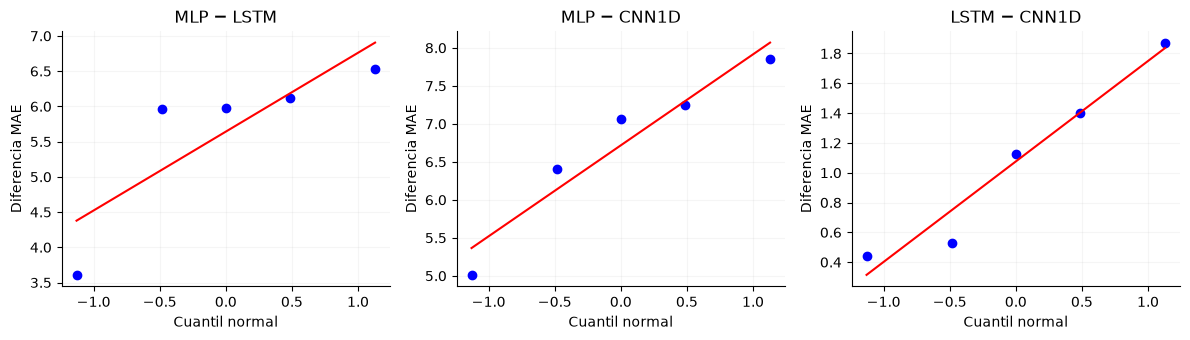

In [73]:
bmk_plot(benchmark_result, 'normalidad', ROOT); plt.show()

**Interpretación.** Las diferencias del piloto que involucran MLP presentan mayor dispersión que LSTM–CNN1D, coherente con sus desviaciones pareadas de 1,16, 1,08 y 0,60 COP/kWh. Con cinco pares, el gráfico Q–Q ofrece información limitada para verificar normalidad en el dimensionamiento.

## 10.11 Métricas globales y por horizonte

MASE usa una escala común por fold, calculada con pares estacionales de entrenamiento a 168 horas. La persistencia utiliza el último precio disponible al origen (o−25 h); las referencias de 48 horas y semanal mantienen el perfil horario. Los IC son temporales y condicionales a las semillas disponibles.

In [74]:
display(benchmark_tables['metricas_globales'][['modelo','mae','mae_IC95_inf','mae_IC95_sup','rmse','mase','sesgo','DE_semillas']].round(4))

,modelo,mae,mae_IC95_inf,mae_IC95_sup,rmse,mase,sesgo,DE_semillas
0,MLP,24.992,22.617,26.511,37.953,0.9424,-2.964,0.0954
1,LSTM,24.624,22.241,26.253,37.773,0.9293,-2.7678,0.1013
2,CNN1D,24.155,21.784,25.754,37.604,0.9118,-4.6981,0.144
3,Semanal,40.157,35.03,44.81,62.444,1.513,-1.1514,0
4,Persistencia disponible,30.181,27.061,32.051,48.848,1.1416,-11.924,0
5,Repetición 48 h,27.309,24.414,29.023,45.034,1.0319,-0.2554,0


In [75]:
display(benchmark_tables['umbrales_entrenamiento'].round(4))

,fold,horas_etiqueta_entrenamiento,MASE_escala,precio_p10_train,precio_p90_train,llenado_q33_train,llenado_q67_train
0,1,157416,25.658,41.523,203.16,0.6278,0.7609
1,2,164448,25.416,42.251,201.07,0.6264,0.762
2,3,171456,26.143,42.8,209.69,0.6234,0.7599
3,4,178464,27.735,43.486,244.78,0.6203,0.7539
4,5,185472,28.337,43.925,250.21,0.6188,0.7501


In [76]:
display(benchmark_tables['metricas_horizonte'].query('horizonte in [1,6,12,24]').round(4))

,modelo,horizonte,MAE,RMSE,MASE,sesgo
0,MLP,1,25.161,38.22,0.9476,1.3919
5,MLP,6,23.467,36.294,0.8838,2.3736
11,MLP,12,27.464,41.095,1.0373,-7.6901
23,MLP,24,21.789,32.663,0.8211,-2.2909
24,LSTM,1,25.339,38.647,0.9544,3.0354
29,LSTM,6,23.962,37.235,0.9025,3.2598
35,LSTM,12,26.821,40.587,1.0142,-7.2271
47,LSTM,24,21.558,32.582,0.8132,-1.1051
48,CNN1D,1,23.522,37.649,0.8866,-0.0383
53,CNN1D,6,22.165,35.702,0.8354,-0.079


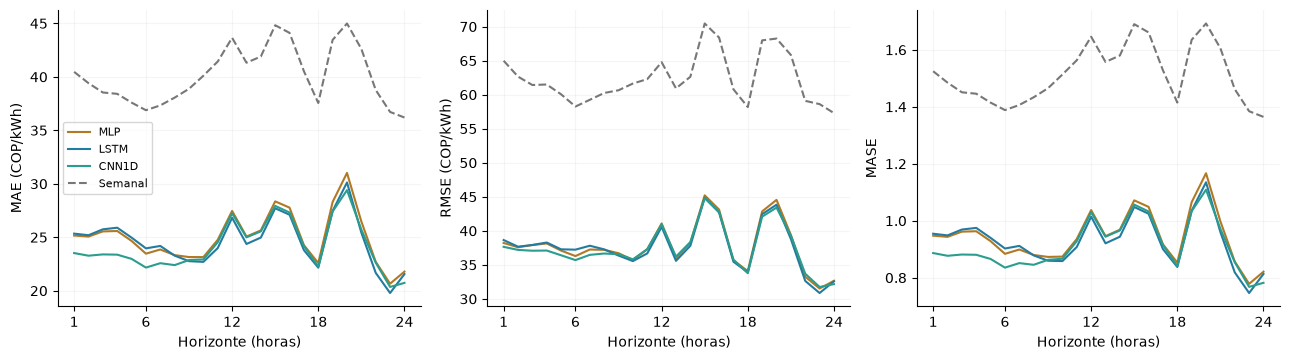

In [77]:
bmk_plot(benchmark_result, 'horizonte', ROOT); plt.show()

**Interpretación.** El MAE alcanza un máximo alrededor del horizonte 20 y disminuye hacia el 23; CNN1D destaca especialmente en los primeros horizontes. El error no aumenta de forma monótona: al emitir siempre a las 00:00, horizonte y hora del día avanzan conjuntamente.

## 10.12 Comparaciones pareadas y relevancia práctica

El signo positivo indica menor MAE del candidato. Se muestran diferencias, efecto d_z, IC simultáneos y reducción relativa frente al primer modelo del par. Holm corrige tres comparaciones principales. TOST contrasta el margen ±2 % mediante dos pruebas de frontera. Los p bootstrap son aproximaciones Monte Carlo con 5000 réplicas.

In [78]:
display(benchmark_tables['comparaciones_bloques'].query('bloque_dias==14')[['referencia','candidato','diferencia_COP_kWh','IC_sim_inf','IC_sim_sup','p_Holm','d_z_diario','d_z_IC95_inf','d_z_IC95_sup']].style.format(precision=4, formatter={'p_Holm':'{:.3g}'}))

,referencia,candidato,diferencia_COP_kWh,IC_sim_inf,IC_sim_sup,p_Holm,d_z_diario,d_z_IC95_inf,d_z_IC95_sup
0,MLP,LSTM,0.3675,-0.1477,0.7760,0.0892,0.0519,-0.0111,0.1047
1,MLP,CNN1D,0.8372,0.4548,1.1739,0.0006,0.1810,0.1130,0.2458
2,LSTM,CNN1D,0.4697,-0.0524,1.0589,0.0892,0.0657,0.0088,0.1425


In [79]:
display(benchmark_tables['comparaciones_bloques'].query('bloque_dias==14')[['referencia','candidato','reduccion_pct','reduccion_IC_sim_inf_pct','reduccion_IC_sim_sup_pct','TOST_p_Holm','supera_delta_2pct','equivalencia_2pct']].round(5))

,referencia,candidato,reduccion_pct,reduccion_IC_sim_inf_pct,reduccion_IC_sim_sup_pct,TOST_p_Holm,supera_delta_2pct,equivalencia_2pct
0,MLP,LSTM,1.4704,-0.61932,3.1812,1,False,False
1,MLP,CNN1D,3.3498,1.8368,4.8313,1,False,False
2,LSTM,CNN1D,1.9074,-0.21902,4.3834,1,False,False


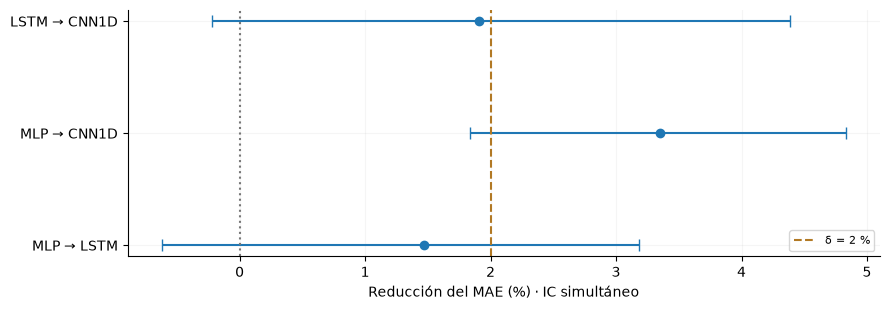

In [80]:
bmk_plot(benchmark_result, 'comparaciones', ROOT); plt.show()

**Interpretación.** La reducción de CNN1D frente a MLP es del 3,35 % y su intervalo simultáneo excluye cero, pero el límite inferior de 1,84 % queda por debajo de δ = 2 %. Los intervalos de las otras dos comparaciones incluyen cero, por lo que sus diferencias medias no quedan establecidas con este contraste.

In [81]:
display(benchmark_tables['comparaciones_bloques'][['bloque_dias','referencia','candidato','SE_temporal','MDE_temporal_COP_kWh','delta_COP_kWh','potencia_temporal_aprox_delta','p_Holm']].round(6))

,bloque_dias,referencia,candidato,SE_temporal,MDE_temporal_COP_kWh,delta_COP_kWh,potencia_temporal_aprox_delta,p_Holm
0,14,MLP,LSTM,0.19547,0.63248,0.49984,0.56477,0.089182
1,14,MLP,CNN1D,0.15074,0.48774,0.49984,0.8217,0.0006
2,14,LSTM,CNN1D,0.23026,0.74504,0.49249,0.39929,0.089182
3,7,MLP,LSTM,0.20868,0.67519,0.49984,0.50052,0.083383
4,7,MLP,CNN1D,0.14794,0.47868,0.49984,0.83761,0.0006
5,7,LSTM,CNN1D,0.23112,0.74782,0.49249,0.39623,0.081584
6,28,MLP,LSTM,0.19858,0.64252,0.49984,0.54898,0.11038
7,28,MLP,CNN1D,0.158,0.51122,0.49984,0.77924,0.0006
8,28,LSTM,CNN1D,0.23918,0.77388,0.49249,0.36886,0.11038


## 10.13 Contrastes temporales y rangos

DM–HLN utiliza pérdida absoluta, HAC Bartlett de 13 días y Holm sobre 72 contrastes. El horizonte efectivo de HLN es un paso diario para cada hora pronosticada. Friedman usa bloques completos no superpuestos de 14 días dentro de fold; Nemenyi se interpreta junto al contraste global. Los bloques pueden conservar dependencia residual.

In [82]:
display(benchmark_tables['DM_horizonte'].query('horizonte in [1,6,12,24]').round(6))

,referencia,candidato,horizonte,diferencia,DM_HLN,p,varianza_HAC,HAC_rezagos_dias,h_efectivo,p_Holm_72
0,MLP,LSTM,1,-0.17824,-0.64646,0.51808,0.075969,13,1,1
5,MLP,LSTM,6,-0.49468,-1.4088,0.15909,0.1232,13,1,1
11,MLP,LSTM,12,0.64303,2.5257,0.011653,0.064775,13,1,0.48941
23,MLP,LSTM,24,0.23111,0.87072,0.38405,0.070399,13,1,1
24,MLP,CNN1D,1,1.6392,5.6567,0,0.083918,13,1,1e-06
29,MLP,CNN1D,6,1.302,4.6503,4e-06,0.078339,13,1,0.000228
35,MLP,CNN1D,12,0.22622,1.0671,0.28609,0.044909,13,1,1
47,MLP,CNN1D,24,1.0554,4.5546,6e-06,0.053659,13,1,0.000353
48,LSTM,CNN1D,1,1.8175,4.1408,3.7e-05,0.19252,13,1,0.002159
53,LSTM,CNN1D,6,1.7967,3.8432,0.000127,0.2184,13,1,0.007092


In [83]:
display(benchmark_tables['Friedman'].round(6)); display(benchmark_tables['rangos'].round(4)); display(benchmark_tables['Nemenyi'].round(6))

,bloques_completos,dias_utilizados,dias_excluidos_resto,estadistico,p,W_Kendall
0,100,1400,61,15.12,0.000521,0.0756


,modelo,rango_medio
0,MLP,2.24
1,LSTM,2.06
2,CNN1D,1.7


,referencia,candidato,diferencia_rangos,q,p_Nemenyi
0,MLP,LSTM,0.18,1.8,0.41059
1,MLP,CNN1D,0.54,5.4,0.000395
2,LSTM,CNN1D,0.36,3.6,0.029371


## 10.14 Segmentos y residuos

Los umbrales de precio y llenado proceden del entrenamiento de cada fold. Los segmentos de precio observado describen retrospectivamente la dificultad. Se analiza el residuo diario medio por ejecución: Ljung–Box a 7/14/28 días, ARCH-LM a 7 y BDS sobre 200 días por fold (dimensiones 2/3, distancia 1,5 DE). Holm se aplica dentro de cada familia de prueba.

In [84]:
display(benchmark_tables['errores_segmentos'].query("segmentacion in ['Precio','Llenado','Fold'] and modelo in ['MLP','LSTM','CNN1D']").round(4))

,modelo,segmentacion,grupo,horas,MAE,RMSE,sesgo
31,MLP,Precio,Alto,10520,39.773,54.44,-15.577
32,MLP,Precio,Central,24544,18.657,28.062,2.4421
33,MLP,Llenado,Alto,10344,19.917,34.256,-3.1399
34,MLP,Llenado,Bajo,13296,27.151,38.951,-1.8975
35,MLP,Llenado,Medio,11424,27.074,39.911,-4.0462
36,MLP,Fold,1,7032,15.754,23.562,-2.8285
37,MLP,Fold,2,7008,26.601,36.724,-3.9178
38,MLP,Fold,3,7008,39.776,54.744,-2.7566
39,MLP,Fold,4,7008,24.231,36.349,-2.8918
40,MLP,Fold,5,7008,18.629,31.351,-2.4259


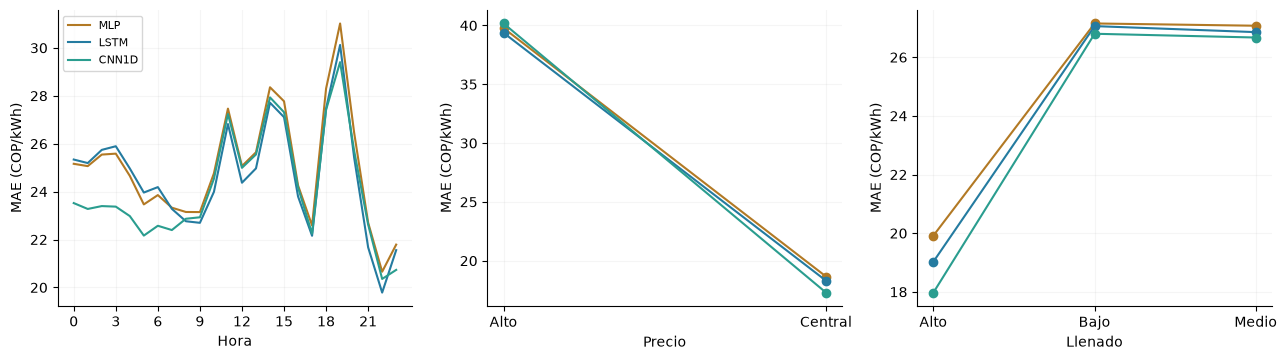

In [85]:
bmk_plot(benchmark_result, 'segmentos', ROOT); plt.show()

**Interpretación.** El mayor error horario aparece hacia las 19:00. En precios altos, LSTM registra el menor MAE (39,37), mientras CNN1D destaca en precios centrales (17,29), que representan el 70 % de las horas; ningún registro integra el grupo de precio bajo. Con llenado alto, el MAE de CNN1D es 17,97 frente a aproximadamente 26,7–26,8 en los otros grupos, asociación que también combina diferencias de fechas y precios.

In [86]:
display(benchmark_tables['residuos_resumen'].style.format(precision=0, formatter={'p_ajustado_min':'{:.3e}'}))

,modelo,prueba,contrastes,rechazos_Holm,p_ajustado_min
0,CNN1D,ARCH-LM,25,18,3.487e-17
1,CNN1D,BDS,50,50,2.503e-40
2,CNN1D,Ljung–Box,75,75,1.165e-35
3,LSTM,ARCH-LM,25,15,2.330e-20
4,LSTM,BDS,50,47,5.069e-39
5,LSTM,Ljung–Box,75,75,1.321e-77
6,MLP,ARCH-LM,25,13,2.537e-14
7,MLP,BDS,50,49,5.009e-40
8,MLP,Ljung–Box,75,75,2.347e-33


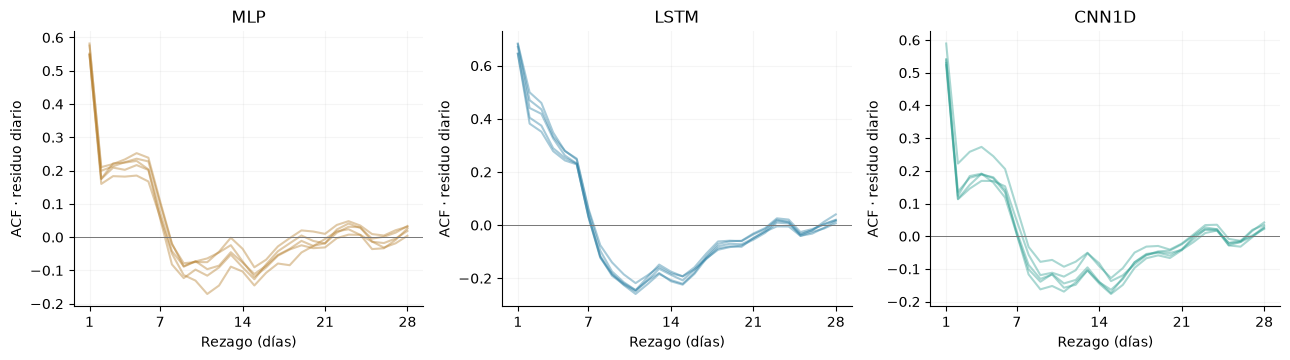

In [87]:
bmk_plot(benchmark_result, 'residuos', ROOT); plt.show()

**Interpretación.** Las cinco semillas conservan autocorrelación en sus errores diarios; Ljung–Box rechaza ausencia de autocorrelación en todos los contrastes mostrados por modelo. La dependencia residual señala estructura temporal que las configuraciones actuales aún no capturan por completo.

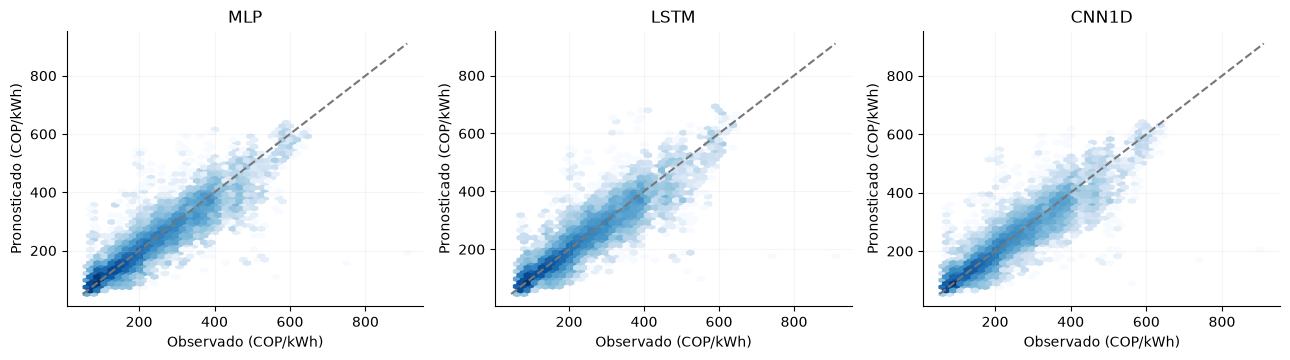

In [88]:
bmk_plot(benchmark_result, 'observado', ROOT); plt.show()

**Interpretación.** La mayor concentración de pares sigue la diagonal, pero algunos precios observados de 800–900 COP/kWh se pronostican cerca de 150–200, evidenciando subestimación de picos. La figura de la semilla 11037 muestra que los errores extremos persisten en las tres familias.

## 10.15 Curvas, estabilidad y costo

Se muestran las cinco semillas del último fold. El MAE de entrenamiento corresponde a lotes con Dropout; la brecha del checkpoint describe el ajuste. Los tiempos son los registrados en el entorno experimental; NR identifica latencia no disponible. La estabilidad por bloques, regímenes y semillas se describe con resultados existentes.

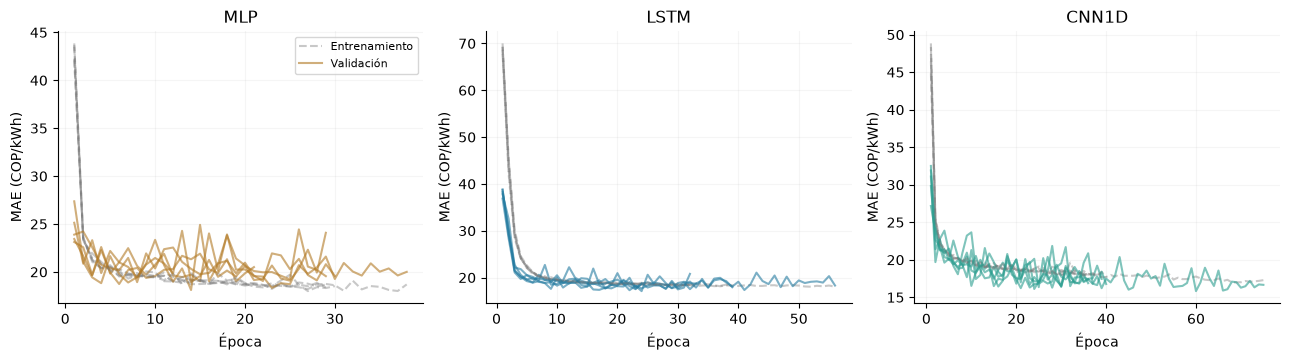

In [89]:
bmk_plot(benchmark_result, 'curvas', ROOT); plt.show()

**Interpretación.** El mayor descenso del error ocurre en las primeras épocas y luego las curvas se estabilizan. MLP presenta oscilaciones de validación más amplias que LSTM, mientras CNN1D mantiene niveles bajos con diferencias entre semillas y duraciones de ajuste distintas.

In [90]:
display(benchmark_tables['brechas_aprendizaje'].groupby('modelo')[['train_MAE_lotes','validacion_MAE','brecha']].agg(['mean','std']).round(4))

train_MAE_lotes        validacion_MAE        brecha       
                  mean    std           mean    std   mean    std
modelo                                                           
CNN1D            17.86 0.8314         24.161 9.1471 6.3008 9.2121
LSTM            17.805 0.9199         24.631 9.2103  6.826 9.3982
MLP             18.218 1.1251         24.998  8.513 6.7797 8.8256

In [91]:
display(benchmark_tables['costos'].round(3).astype(object).fillna('NR'))

,modelo,configuraciones,ajustes_busqueda,segundos_busqueda,parametros,segundos_ajuste_elegido_media,segundos_ajuste_elegido_DE,segundos_elegidos_total,latencia_inferencia_ms
0,MLP,64,1600,2358.2,263576,1.433,0.422,35.815,NR
1,LSTM,64,1600,19371,27928,7.153,1.992,178.83,NR
2,CNN1D,64,1600,18943,43224,2.283,0.782,57.075,NR


## 10.16 Síntesis del benchmark

In [92]:
from IPython.display import Markdown
primary = benchmark_tables['comparaciones_bloques'].query('bloque_dias==14')
cnn_mlp = primary.query("referencia=='MLP' and candidato=='CNN1D'").iloc[0]
pilot_plan = benchmark_tables['potencia_semillas'].query("fuente=='Piloto'")

In [93]:
display(Markdown(f"CNN1D presenta el menor MAE de selección (**24,155 COP/kWh**), seguido de LSTM (**24,624**) y MLP (**24,992**). Frente a MLP, la reducción estimada es **{cnn_mlp.reduccion_pct:.2f} %**, con p ajustado **{cnn_mlp.p_Holm:.4f}** y límite inferior simultáneo de **{cnn_mlp.reduccion_IC_sim_inf_pct:.2f} %**. El intervalo incluye mejoras inferiores a δ = 2 %. Las comparaciones globales restantes no alcanzan α = 0,05 con el bootstrap principal y TOST no establece equivalencia entre las familias.\n\nEl dimensionamiento del piloto orienta a **{benchmark_result['audit']['recommended_seeds_from_pilot']} semillas por familia** para el efecto previsto bajo el supuesto de diferencias normales, condicionado al mismo periodo. La incertidumbre temporal se describe por separado. Friedman y Nemenyi evalúan rangos por bloque, mientras el contraste principal compara magnitud media del error; sus resultados se interpretan según esos estimandos.\n\nLa autocorrelación persiste en los residuos diarios. El rechazo de BDS también puede reflejar esa dependencia y no aísla no linealidad. CNN1D se conserva como referencia descriptiva de validación. La sección 10.17 evalúa las tres configuraciones congeladas sobre prueba; la robustez ante perturbaciones de entrada y la latencia por pronóstico quedan pendientes."))

CNN1D presenta el menor MAE de selección (**24,155 COP/kWh**), seguido de LSTM (**24,624**) y MLP (**24,992**). Frente a MLP, la reducción estimada es **3.35 %**, con p ajustado **0.0006** y límite inferior simultáneo de **1.84 %**. El intervalo incluye mejoras inferiores a δ = 2 %. Las comparaciones globales restantes no alcanzan α = 0,05 con el bootstrap principal y TOST no establece equivalencia entre las familias.

El dimensionamiento del piloto orienta a **38 semillas por familia** para el efecto previsto bajo el supuesto de diferencias normales, condicionado al mismo periodo. La incertidumbre temporal se describe por separado. Friedman y Nemenyi evalúan rangos por bloque, mientras el contraste principal compara magnitud media del error; sus resultados se interpretan según esos estimandos.

La autocorrelación persiste en los residuos diarios. El rechazo de BDS también puede reflejar esa dependencia y no aísla no linealidad. CNN1D se conserva como referencia descriptiva de validación. La sección 10.17 evalúa las tres configuraciones congeladas sobre prueba; la robustez ante perturbaciones de entrada y la latencia por pronóstico quedan pendientes.

## 10.17 Evaluación de las arquitecturas congeladas

La selección por MAE de validación se conserva: CNN1D C3 de 24 horas, LSTM L2 de 72 horas y MLP M3 de 24 horas. Se realizaron cinco ajustes finales por familia con desarrollo 2000–2021. El número de épocas se fijó mediante la mediana de la mejor época de sus 25 ejecuciones de desarrollo: 23, 22 y 18, respectivamente. Los modelos se evaluaron sobre 2022–2025 con pesos y escaladores fijos.

Cada origen diario a las 00:00 predice 24 precios. Se utilizan observaciones con los rezagos establecidos, sin actualizar parámetros durante prueba. El protocolo `PROTOCOLO_EVALUACION_FINAL_2026-11-07.md` y `configs/final_evaluation.json` registran las decisiones y huellas anteriores al cálculo de errores. La evaluación es retrospectiva y conserva los supuestos de disponibilidad del estudio.

Las celdas siguientes contienen el código del congelamiento, ajuste y evaluación. La ejecución documental reproduce las métricas desde las predicciones guardadas; no entrena ni carga las series de prueba.

In [94]:
import hashlib

In [95]:
import json

In [96]:
import time

In [97]:
from pathlib import Path

In [98]:
import numpy as np

In [99]:
import pandas as pd

In [100]:
import torch

In [101]:
from sklearn.preprocessing import StandardScaler

In [102]:
def fe_sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

In [103]:
def fe_json(path, value, immutable=False):
    path = Path(path)
    encoded = json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False) + '\n'
    if immutable and path.exists():
        if json.loads(path.read_text(encoding='utf-8')) != value:
            raise RuntimeError('Artefacto congelado incompatible: ' + str(path))
        return
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(encoded, encoding='utf-8')
    temporary.replace(path)

In [104]:
def fe_origins(features, target, lookback, start, end, common_lookback=336):
    index = features.index
    if index.tz is None or index.has_duplicates or (not index.is_monotonic_increasing):
        raise ValueError('Calendario no válido.')
    if not np.all(np.diff(index.as_unit('ns').asi8) == pd.Timedelta(hours=1).value):
        raise ValueError('Hay horas faltantes.')
    origins = np.flatnonzero((index >= pd.Timestamp(start)) & (index < pd.Timestamp(end)) & (index.hour == 0))
    origins = origins[(origins >= common_lookback) & (origins + 24 <= len(index))]
    origins = origins[index[origins + 23] < pd.Timestamp(end)]
    flags = np.isfinite(features.to_numpy()).all(axis=1)
    cumulative = np.r_[0, np.cumsum(~flags)]
    origins = origins[cumulative[origins] - cumulative[origins - common_lookback] == 0]
    yy = np.asarray(target)
    valid_y = np.r_[0, np.cumsum(~np.isfinite(yy))]
    origins = origins[valid_y[origins + 24] - valid_y[origins] == 0]
    if not len(origins) or lookback > common_lookback:
        raise ValueError('No hay ventanas comunes admisibles.')
    return origins

In [105]:
def fe_training_arrays(features, target, origins, lookback):
    positions = origins[:, None] - lookback + np.arange(lookback)
    rows = np.unique(positions)
    scaler = StandardScaler().fit(features.iloc[rows])
    scaled = scaler.transform(features.iloc[rows]).astype(np.float32)
    x = scaled[np.searchsorted(rows, positions)]
    y = np.asarray(target)[origins[:, None] + np.arange(24)].astype(np.float32)
    if not np.isfinite(x).all() or not np.isfinite(y).all() or np.any(y < 0):
        raise ValueError('Entradas o etiquetas no válidas.')
    target_scale = float(y.std())
    used = np.zeros(len(target), dtype=bool)
    used[(origins[:, None] + np.arange(24)).ravel()] = True
    pairs = np.flatnonzero(used)[np.flatnonzero(used) >= 168]
    pairs = pairs[used[pairs - 168]]
    mase_scale = float(np.abs(np.asarray(target)[pairs] - np.asarray(target)[pairs - 168]).mean())
    if not target_scale > 0 or not mase_scale > 0:
        raise ValueError('Escala de entrenamiento no positiva.')
    audit = dict(feature_names=list(features.columns), feature_mean=scaler.mean_.tolist(), feature_scale=scaler.scale_.tolist(), target_scale=target_scale, mase_scale=mase_scale, fit_rows=len(rows), train_windows=len(origins), fit_start=features.index[rows[0]].isoformat(), fit_end=features.index[rows[-1]].isoformat(), last_train_origin=features.index[origins[-1]].isoformat(), last_train_label=features.index[origins[-1] + 23].isoformat(), train_origins_sha256=hashlib.sha256(features.index[origins].as_unit('ns').asi8.tobytes()).hexdigest())
    return (x, y, audit)

In [106]:
def fe_freeze(root, architectures):
    """Se ejecuta antes de entrenar y sin cargar valores de prueba."""
    root = Path(root)
    config_path = root / 'configs/final_evaluation.json'
    if config_path.exists():
        frozen = json.loads(config_path.read_text(encoding='utf-8'))
        fe_verify_freeze(root, frozen)
        return frozen
    historical = json.loads((root / 'results/variant_search/configuration.json').read_text(encoding='utf-8'))
    per_seed = pd.read_csv(root / 'results/variant_search/metrics_per_seed.csv')
    runs = pd.read_csv(root / 'results/variant_search/metrics.csv')
    summary = per_seed.groupby('candidate').mae.mean()
    candidates = runs[['candidate', 'family', 'architecture', 'lookback', 'ridge']].drop_duplicates()
    candidates = candidates.merge(summary.rename('mae_validation'), on='candidate')
    chosen = candidates.sort_values(['mae_validation', 'candidate']).groupby('family', sort=True).head(1)
    saved = pd.read_csv(root / 'results/variant_search/best_by_family.csv')
    assert dict(zip(chosen.family, chosen.candidate)) == dict(zip(saved.family, saved.candidate))
    pipeline = build_training_pipeline(dict(load_pipeline_config(), lookback_hours=336))
    features, target = (pipeline['features'], pipeline['target'].to_numpy())
    origins = fe_origins(features, target, 336, pipeline['config']['development_start'], pipeline['config']['development_end_exclusive'])
    family_config = []
    for row in chosen.sort_values('family').itertuples():
        epochs = int(np.median(runs.loc[runs.candidate == row.candidate, 'best_epoch']))
        x, y, preprocessing = fe_training_arrays(features, target, origins, int(row.lookback))
        path = f'results/final_evaluation/preprocessing/{row.family}.json'
        fe_json(root / path, preprocessing, immutable=True)
        family_config.append(dict(family=row.family, candidate=row.candidate, architecture=row.architecture, architecture_spec=architectures[row.architecture], lookback=int(row.lookback), ridge=float(row.ridge), epochs=epochs, selection_mae=float(row.mae_validation), preprocessing=path, preprocessing_sha256=fe_sha(root / path)))
        del x, y
    source_paths = ['scripts/evaluate_frozen_models.py', 'src/colombia_energy/final_evaluation.py', 'scripts/train_variants.py', 'src/colombia_energy/pipeline.py', 'src/colombia_energy/data.py', 'src/colombia_energy/runtime.py', 'PROTOCOLO_EVALUACION_FINAL_2026-11-07.md', 'results/variant_search/best_by_family.csv', 'results/variant_search/metrics.csv', 'results/variant_search/metrics_per_seed.csv', 'configs/training_pipeline.json', 'data/test_freeze.json']
    data_paths = sorted((root / 'data/numeric').glob('*/*.csv.gz'))
    frozen = dict(version='1.0', frozen_at_utc=pd.Timestamp.now(tz='UTC').isoformat(), test_start=pipeline['config']['test_start'], test_end_exclusive=pipeline['config']['test_end_exclusive'], development_start=pipeline['config']['development_start'], development_end_exclusive=pipeline['config']['development_end_exclusive'], pipeline=pipeline['config'], families=family_config, seeds=historical['seeds'], dropout=historical['dropout'], lr=historical['lr'], batch_size=historical['batch_size'], weight_decay=0.0, gradient_clip_norm=1.0, output='Softplus', epoch_rule='median_best_epoch_over_25_development_runs_per_selected_family', fit_policy='one_fixed_fit_on_full_development_per_family_and_seed_no_test_updates', prediction_policy='daily_rolling_inputs_with_fixed_weights_and_development_scalers', aggregation='mean_of_per_seed_metrics_not_prediction_ensemble', primary_metric='MAE', secondary_metrics=['RMSE', 'MASE', 'R2', 'bias'], bootstrap=dict(block_days=14, replicates=5000, seed=20261106, confidence=0.95), delta_relative=0.02, common_lookback=336, feature_names=list(features.columns), source_sha256={p: fe_sha(root / p) for p in source_paths}, numeric_data_sha256={p.relative_to(root).as_posix(): fe_sha(p) for p in data_paths}, test_values_read_at_freeze=False, hyperparameter_search_on_test=False)
    fe_json(config_path, frozen, immutable=True)
    return frozen

In [107]:
def fe_verify_freeze(root, frozen):
    for section in ['source_sha256', 'numeric_data_sha256']:
        for name, sha in frozen[section].items():
            if fe_sha(Path(root) / name) != sha:
                raise RuntimeError('Cambio posterior al congelamiento: ' + name)
    for family in frozen['families']:
        if fe_sha(Path(root) / family['preprocessing']) != family['preprocessing_sha256']:
            raise RuntimeError('Preprocesamiento congelado modificado.')
    assert len(frozen['families']) == 3 and len(frozen['seeds']) == 5

In [108]:
def fe_fit(root, frozen, model_factory, penalty, device, threads):
    """Sólo desarrollo: épocas fijas, sin parada ni selección con prueba."""
    root = Path(root)
    fe_verify_freeze(root, frozen)
    output = root / 'results/final_evaluation'
    fit_path = output / 'fit_configuration.json'
    environment = runtime_environment(device, threads)
    fit_config = dict(freeze_sha256=fe_sha(root / 'configs/final_evaluation.json'), runtime=environment)
    fe_json(fit_path, fit_config, immutable=True)
    pipeline = build_training_pipeline(frozen['pipeline'])
    features, target = (pipeline['features'], pipeline['target'].to_numpy())
    origins = fe_origins(features, target, 336, frozen['development_start'], frozen['development_end_exclusive'])
    rows = []
    for family in frozen['families']:
        xx, yy, preprocessing = fe_training_arrays(features, target, origins, family['lookback'])
        if preprocessing != json.loads((root / family['preprocessing']).read_text(encoding='utf-8')):
            raise RuntimeError('El entrenamiento no reproduce los escaladores congelados.')
        x = torch.as_tensor(xx, device=device)
        y = torch.as_tensor(yy / preprocessing['target_scale'], device=device)
        for seed in frozen['seeds']:
            folder = output / 'models' / family['family'] / str(seed)
            folder.mkdir(parents=True, exist_ok=True)
            completed = folder / 'fit.json'
            if completed.exists():
                row = json.loads(completed.read_text(encoding='utf-8'))
                if fe_sha(root / row['checkpoint']) != row['checkpoint_sha256']:
                    raise RuntimeError('Checkpoint alterado.')
                rows.append(row)
                continue
            seed_training(seed, device)
            model = model_factory(family['architecture'], family['lookback'], len(frozen['feature_names']), frozen['dropout']).to(device)
            optimizer = torch.optim.Adam(model.parameters(), lr=frozen['lr'], weight_decay=0.0)
            curves = []
            synchronize_device(device)
            start = time.perf_counter()
            for epoch in range(1, family['epochs'] + 1):
                model.train()
                absolute = 0.0
                regularization = 0.0
                for ix in torch.randperm(len(x), device=device).split(frozen['batch_size']):
                    optimizer.zero_grad(set_to_none=True)
                    mae = torch.nn.functional.l1_loss(model(x[ix]), y[ix])
                    ridge = penalty(model)
                    loss = mae + family['ridge'] * ridge
                    if not torch.isfinite(loss):
                        raise FloatingPointError('Pérdida final no finita.')
                    loss.backward()
                    torch.nn.utils.clip_grad_norm_(model.parameters(), frozen['gradient_clip_norm'])
                    optimizer.step()
                    absolute += float(mae.detach()) * len(ix)
                    regularization += float(ridge.detach()) * len(ix)
                curves.append(dict(epoch=epoch, train_mae_cop_kwh=absolute / len(x) * preprocessing['target_scale'], ridge_unweighted=regularization / len(x)))
                print(f"Ajuste final {family['family']} semilla {seed}: {epoch}/{family['epochs']} épocas", flush=True)
            synchronize_device(device)
            checkpoint = folder / 'checkpoint.pt'
            torch.save(dict(state_dict={k: v.detach().cpu() for k, v in model.state_dict().items()}, freeze_sha256=fit_config['freeze_sha256'], family=family, seed=seed, feature_names=frozen['feature_names'], preprocessing=preprocessing), checkpoint)
            pd.DataFrame(curves).to_csv(folder / 'curves.csv', index=False)
            row = dict(family=family['family'], candidate=family['candidate'], seed=seed, epochs=family['epochs'], parameters=sum((p.numel() for p in model.parameters())), train_windows=len(x), seconds=time.perf_counter() - start, checkpoint=checkpoint.relative_to(root).as_posix(), checkpoint_sha256=fe_sha(checkpoint), last_train_label=preprocessing['last_train_label'], test_values_read=False)
            fe_json(completed, row, immutable=True)
            rows.append(row)
            del model, optimizer
        del x, y, xx, yy
    pd.DataFrame(rows).to_csv(output / 'fit_metrics.csv', index=False)
    model_manifest = output / 'models_frozen.json'
    if model_manifest.exists():
        saved = json.loads(model_manifest.read_text(encoding='utf-8'))
        if saved['fits'] != rows or saved['configuration_sha256'] != fit_config['freeze_sha256']:
            raise RuntimeError('Los pesos finales ya están congelados con otro contenido.')
    else:
        fe_json(model_manifest, dict(frozen_at_utc=pd.Timestamp.now(tz='UTC').isoformat(), configuration_sha256=fit_config['freeze_sha256'], fits=rows, test_values_read=False), immutable=True)
    return rows

In [109]:
def fe_released_features(hourly, hydrology, config, names):
    """Misma transformación causal que desarrollo; admite el calendario de evaluación."""
    index = hourly.index
    hourly_names = [n for n in names if n in hourly.columns]
    features = hourly[hourly_names].shift(config['hourly_release_lag_hours']).copy()
    hydro_names = ['llenado_valor_original', 'reserva_util_kwh', 'capacidad_util_kwh', 'aportes_kwh_dia']
    released = hydrology[hydro_names].copy()
    released.index = released.index + pd.Timedelta(days=config['hydrology_release_lag_days'])
    features = features.join(released.reindex(index, method='ffill'))
    phases = {'hour': index.hour / 24, 'week': (index.day_of_week + index.hour / 24) / 7, 'year': (index.day_of_year - 1 + index.hour / 24) / np.where(index.is_leap_year, 366, 365)}
    for name, phase in phases.items():
        features[name + '_sin'] = np.sin(2 * np.pi * phase)
        features[name + '_cos'] = np.cos(2 * np.pi * phase)
    assert_e1_features(features.columns)
    return features[names]

In [110]:
def fe_scores(actual, predicted, mase_scale):
    actual = np.asarray(actual, dtype=np.float64)
    predicted = np.asarray(predicted, dtype=np.float64)
    if actual.shape != predicted.shape or not np.isfinite(actual).all() or (not np.isfinite(predicted).all()):
        raise ValueError('Predicciones y etiquetas incompatibles.')
    error = predicted - actual
    mse = float(np.square(error).mean())
    variance = float(np.square(actual - actual.mean()).sum())
    return dict(mae=float(np.abs(error).mean()), rmse=float(np.sqrt(mse)), mase=float(np.abs(error).mean() / mase_scale), r2=float(1 - np.square(error).sum() / variance) if variance else 0.0, bias=float(error.mean()), n_values=error.size)

In [111]:
def fe_bootstrap_weights(n, length, replicates, seed):
    if length < 1 or n < length:
        raise ValueError('Bloques insuficientes.')
    rng = np.random.default_rng(seed)
    starts = rng.integers(0, n - length + 1, size=(replicates, int(np.ceil(n / length))))
    positions = (starts[:, :, None] + np.arange(length)).reshape(replicates, -1)[:, :n]
    weights = np.zeros((replicates, n), dtype=np.int16)
    np.add.at(weights, (np.arange(replicates)[:, None], positions), 1)
    assert np.all(weights.sum(axis=1) == n)
    return weights.astype(np.float64) / n

In [112]:
def fe_summarize(actual, predictions, baselines, dates_ns, frozen, mase_scale):
    dates = pd.DatetimeIndex(pd.to_datetime(dates_ns, utc=True)).tz_convert('America/Bogota')
    expected = pd.date_range(frozen['test_start'], pd.Timestamp(frozen['test_end_exclusive']) - pd.Timedelta(days=1), freq='D')
    if not np.array_equal(dates.as_unit('ns').asi8, expected.as_unit('ns').asi8):
        raise ValueError('Faltan orígenes diarios de prueba o hay duplicados.')
    settings = frozen['bootstrap']
    weights = fe_bootstrap_weights(len(dates), settings['block_days'], settings['replicates'], settings['seed'])
    per_seed = []
    global_rows = []
    horizon = []
    annual = []
    all_predictions = {**predictions, **{name: arr[None, :, :] for name, arr in baselines.items()}}
    weekly_mae = fe_scores(actual, baselines['Semanal'], mase_scale)['mae']
    for name, pp in all_predictions.items():
        values = []
        for i, pred in enumerate(pp):
            score = fe_scores(actual, pred, mase_scale)
            values.append(score)
            per_seed.append(dict(model=name, seed=frozen['seeds'][i] if name in predictions else -1, **score))
        daily = np.abs(pp.astype(np.float64) - actual[None, :, :]).mean(axis=(0, 2))
        resampled = weights @ daily
        low, high = np.quantile(resampled, [0.025, 0.975])
        row = dict(model=name, **{k: float(np.mean([s[k] for s in values])) for k in ['mae', 'rmse', 'mase', 'r2', 'bias']}, mae_sd_seeds=float(np.std([s['mae'] for s in values], ddof=1)) if len(values) > 1 else 0.0, mae_ci95_low=float(low), mae_ci95_high=float(high), seeds=len(pp), origins=len(dates), n_values=actual.size, reduction_vs_weekly_pct=100 * (1 - np.mean([s['mae'] for s in values]) / weekly_mae))
        global_rows.append(row)
        for h in range(24):
            scores = [fe_scores(actual[:, h], pred[:, h], mase_scale) for pred in pp]
            horizon.append(dict(model=name, horizon=h + 1, hour=h, **{k: float(np.mean([s[k] for s in scores])) for k in ['mae', 'rmse', 'mase', 'r2', 'bias']}))
        for year in sorted(set(dates.year)):
            mask = dates.year == year
            scores = [fe_scores(actual[mask], pred[mask], mase_scale) for pred in pp]
            annual.append(dict(model=name, year=int(year), origins=int(mask.sum()), **{k: float(np.mean([s[k] for s in scores])) for k in ['mae', 'rmse', 'mase', 'r2', 'bias']}))
    return dict(metrics_global=pd.DataFrame(global_rows).sort_values('mae'), metrics_per_seed=pd.DataFrame(per_seed), metrics_horizon=pd.DataFrame(horizon), metrics_year=pd.DataFrame(annual))

In [113]:
def fe_evaluate(root, frozen, model_factory, device):
    """Acceso explícito a prueba sólo con configuración y todos los pesos congelados."""
    root = Path(root)
    out = root / 'results/final_evaluation'
    fe_verify_freeze(root, frozen)
    if (out / 'completed.json').exists():
        return fe_load_results(root)
    models = json.loads((out / 'models_frozen.json').read_text(encoding='utf-8'))
    assert models['configuration_sha256'] == fe_sha(root / 'configs/final_evaluation.json')
    assert len(models['fits']) == 15 and (not models['test_values_read'])
    for row in models['fits']:
        assert fe_sha(root / row['checkpoint']) == row['checkpoint_sha256']
    manifest = json.loads((root / 'data/test_freeze.json').read_text(encoding='utf-8'))
    for entry in manifest['files']:
        assert fe_sha(root / entry['path']) == entry['sha256']
    fe_json(out / 'evaluation_access.json', dict(started_at_utc=pd.Timestamp.now(tz='UTC').isoformat(), configuration_sha256=fe_sha(root / 'configs/final_evaluation.json'), models_manifest_sha256=fe_sha(out / 'models_frozen.json'), period_start=frozen['test_start'], period_end_exclusive=frozen['test_end_exclusive']))
    hourly = pd.concat([load_numeric('train'), load_numeric('validation'), load_numeric('test', allow_test=True)]).sort_index()
    hydro = pd.concat([load_numeric('train', table='hydrology'), load_numeric('validation', table='hydrology'), load_numeric('test', table='hydrology', allow_test=True)]).sort_index()
    features = fe_released_features(hourly, hydro, frozen['pipeline'], frozen['feature_names'])
    dev_end = pd.Timestamp(frozen['development_end_exclusive'])
    expected_features = numeric_feature_frame(hourly.loc[hourly.index < dev_end], hydro.loc[hydro.index < dev_end], frozen['pipeline'])
    np.testing.assert_allclose(features.loc[features.index < dev_end].to_numpy(), expected_features.to_numpy(), equal_nan=True, rtol=0, atol=0)
    target = hourly[TARGET].to_numpy(dtype=np.float64)
    origins = fe_origins(features, target, 336, frozen['test_start'], frozen['test_end_exclusive'])
    dates_ns = features.index[origins].as_unit('ns').asi8
    actual = target[origins[:, None] + np.arange(24)]
    baselines = {'Semanal': target[origins[:, None] + np.arange(24) - 168], 'Persistencia disponible': np.repeat(target[origins - 25, None], 24, axis=1), 'Repetición 48 h': target[origins[:, None] + np.arange(24) - 48]}
    predictions = {}
    inference = []
    freeze_sha = fe_sha(root / 'configs/final_evaluation.json')
    for family in frozen['families']:
        lookback = family['lookback']
        positions = origins[:, None] - lookback + np.arange(lookback)
        prep = json.loads((root / family['preprocessing']).read_text(encoding='utf-8'))
        rows = np.unique(positions)
        scaled = ((features.iloc[rows].to_numpy() - np.asarray(prep['feature_mean'])) / np.asarray(prep['feature_scale'])).astype(np.float32)
        xx = torch.as_tensor(scaled[np.searchsorted(rows, positions)], device=device)
        family_predictions = []
        for seed in frozen['seeds']:
            folder = out / 'models' / family['family'] / str(seed)
            checkpoint = torch.load(folder / 'checkpoint.pt', map_location=device, weights_only=True)
            assert checkpoint['freeze_sha256'] == freeze_sha and checkpoint['seed'] == seed
            model = model_factory(family['architecture'], lookback, len(frozen['feature_names']), frozen['dropout']).to(device)
            model.load_state_dict(checkpoint['state_dict'])
            model.eval()
            synchronize_device(device)
            start = time.perf_counter()
            with torch.no_grad():
                pred = (torch.cat([model(z) for z in xx.split(frozen['batch_size'])]) * prep['target_scale']).cpu().numpy()
            synchronize_device(device)
            if not np.isfinite(pred).all() or np.any(pred < 0):
                raise ValueError('Predicción no válida.')
            inference.append(dict(family=family['family'], seed=seed, batch_size=frozen['batch_size'], origins=len(origins), seconds=time.perf_counter() - start))
            family_predictions.append(pred)
            del model, checkpoint
        predictions[family['family']] = np.stack(family_predictions)
        del xx
    archive = dict(actual=actual, origins_ns=dates_ns, **{'prediction_' + k: v for k, v in predictions.items()}, baseline_weekly=baselines['Semanal'], baseline_persistence=baselines['Persistencia disponible'], baseline_48h=baselines['Repetición 48 h'])
    np.savez_compressed(out / 'predictions.npz', **archive)
    mase_scale = json.loads((root / frozen['families'][0]['preprocessing']).read_text(encoding='utf-8'))['mase_scale']
    tables = fe_summarize(actual, predictions, baselines, dates_ns, frozen, mase_scale)
    for name, table in tables.items():
        table.to_csv(out / (name + '.csv'), index=False)
    pd.DataFrame(inference).to_csv(out / 'inference_timing.csv', index=False)
    fe_json(out / 'completed.json', dict(completed_at_utc=pd.Timestamp.now(tz='UTC').isoformat(), configuration_sha256=freeze_sha, models_manifest_sha256=fe_sha(out / 'models_frozen.json'), predictions_sha256=fe_sha(out / 'predictions.npz'), families=3, seeds=5, final_fits=15, origins=len(origins), hourly_targets=actual.size, first_origin=str(features.index[origins[0]]), last_origin=str(features.index[origins[-1]]), test_values_read=True, test_used_for_selection=False, weights_updated_during_test=False, scalers_fit_on_test=False, raw_data_modified=False, mase_scale=mase_scale, metric_files_sha256={name + '.csv': fe_sha(out / (name + '.csv')) for name in tables}))
    return dict(tables=tables, config=frozen, audit=json.loads((out / 'completed.json').read_text(encoding='utf-8')))

In [114]:
def fe_load_results(root):
    """Recalcula métricas desde predicciones guardadas sin leer series ni entrenar."""
    root = Path(root)
    out = root / 'results/final_evaluation'
    frozen = json.loads((root / 'configs/final_evaluation.json').read_text(encoding='utf-8'))
    fe_verify_freeze(root, frozen)
    audit = json.loads((out / 'completed.json').read_text(encoding='utf-8'))
    assert audit['configuration_sha256'] == fe_sha(root / 'configs/final_evaluation.json')
    assert audit['predictions_sha256'] == fe_sha(out / 'predictions.npz')
    for name, sha in audit['metric_files_sha256'].items():
        assert fe_sha(out / name) == sha
    with np.load(out / 'predictions.npz', allow_pickle=False) as saved:
        actual = saved['actual']
        origins = saved['origins_ns']
        predictions = {row['family']: saved['prediction_' + row['family']] for row in frozen['families']}
        baselines = {'Semanal': saved['baseline_weekly'], 'Persistencia disponible': saved['baseline_persistence'], 'Repetición 48 h': saved['baseline_48h']}
        assert all((p.shape == (5, len(actual), 24) for p in predictions.values()))
        tables = fe_summarize(actual, predictions, baselines, origins, frozen, audit['mase_scale'])
    for name, table in tables.items():
        pd.testing.assert_frame_equal(table.reset_index(drop=True), pd.read_csv(out / (name + '.csv')).reset_index(drop=True), check_dtype=False, rtol=1e-10, atol=1e-10)
    return dict(tables=tables, config=frozen, audit=audit)

In [115]:
def fe_plot(result, kind, root):
    import matplotlib.pyplot as plt
    colors = {'MLP': '#b67a20', 'LSTM': '#247ba0', 'CNN1D': '#2a9d8f'}
    tables = result['tables']
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    if kind == 'metricas_prueba':
        g = tables['metrics_global'].query("model in ['MLP','LSTM','CNN1D']").sort_values('mae')
        axes[0].bar(g.model, g.mae, color=[colors[n] for n in g.model])
        axes[0].errorbar(g.model, g.mae, yerr=np.maximum(0, np.vstack([g.mae - g.mae_ci95_low, g.mae_ci95_high - g.mae])), fmt='none', ecolor='#333', capsize=5)
        for row in tables['metrics_global'].query("model not in ['MLP','LSTM','CNN1D']").itertuples():
            axes[0].axhline(row.mae, linestyle='--', alpha=0.6, label=row.model)
        axes[0].set_ylabel('MAE (COP/kWh)')
        axes[0].legend(fontsize=8)
        for name, color in colors.items():
            h = tables['metrics_horizon'].query('model==@name')
            axes[1].plot(h.hour, h.mae, label=name, color=color)
        axes[1].set_xlabel('Hora objetivo / horizonte − 1')
        axes[1].set_ylabel('MAE (COP/kWh)')
        axes[1].legend()
    elif kind == 'regimenes_prueba':
        for name, color in colors.items():
            g = tables['metrics_year'].query('model==@name')
            axes[0].plot(g.year, g.mae, 'o-', color=color, label=name)
            axes[1].plot(g.year, g.bias, 'o-', color=color, label=name)
        axes[0].set_ylabel('MAE (COP/kWh)')
        axes[1].set_ylabel('Sesgo: predicción − observado (COP/kWh)')
        axes[1].axhline(0, color='#777', linestyle='--')
        for ax in axes:
            ax.set_xticks([2022, 2023, 2024, 2025])
            ax.set_xlabel('Año')
            ax.legend()
    else:
        raise ValueError(kind)
    for ax in axes:
        ax.grid(alpha=0.15)
        ax.spines[['top', 'right']].set_visible(False)
    fig.tight_layout()
    folder = Path(root) / 'results/final_evaluation/figures'
    folder.mkdir(exist_ok=True)
    fig.savefig(folder / (kind + '.png'), dpi=160, bbox_inches='tight')
    return fig

In [116]:
final_result = fe_load_results(ROOT)
final_tables = final_result['tables']
final_config = final_result['config']
assert final_result['audit']['origins'] == 1461
assert final_result['audit']['hourly_targets'] == 35064
assert not final_result['audit']['test_used_for_selection']

### Configuraciones y métricas globales

Se informa la media de las métricas de cinco semillas, calculadas sobre las mismas 35064 horas. La DE del MAE caracteriza la inicialización. Los IC95 % marginales del MAE usan bloques móviles de 14 días y 5000 réplicas sobre la pérdida diaria media entre semillas. MASE utiliza una escala semanal calculada exclusivamente con etiquetas de desarrollo. Las referencias semanal, persistencia disponible y repetición a 48 horas respetan los rezagos del protocolo.

In [117]:
display(pd.DataFrame([{k: f[k] for k in ['family','candidate','lookback','ridge','epochs']} for f in final_config['families']]))
display(final_tables['metrics_global'][['model','mae','mae_sd_seeds','mae_ci95_low','mae_ci95_high','rmse','mase','r2','bias','reduction_vs_weekly_pct']].round(4))

,family,candidate,lookback,ridge,epochs
0,CNN1D,C3_h24_l2_0.0001,24,0.0001,23
1,LSTM,L2_h72_l2_0.001,72,0.001,22
2,MLP,M3_h24_l2_0.001,24,0.001,18


,model,mae,mae_sd_seeds,mae_ci95_low,mae_ci95_high,rmse,mase,r2,bias,reduction_vs_weekly_pct
0,CNN1D,81.011,2.4189,67.613,96.999,155.91,2.8624,0.8134,-17.381,39.379
5,Repetición 48 h,81.713,0,67.422,98.873,169.75,2.8872,0.7788,0.0775,38.854
2,MLP,84.015,1.4564,70.192,100.89,161.71,2.9686,0.7992,-17.572,37.132
4,Persistencia disponible,87.38,0,71.361,106.9,180.03,3.0875,0.7512,-15.104,34.614
1,LSTM,101.12,1.3097,79.274,128.58,205.92,3.573,0.6745,-44.184,24.332
3,Semanal,133.64,0,110.56,159.8,235.2,4.7219,0.5754,0.5423,0


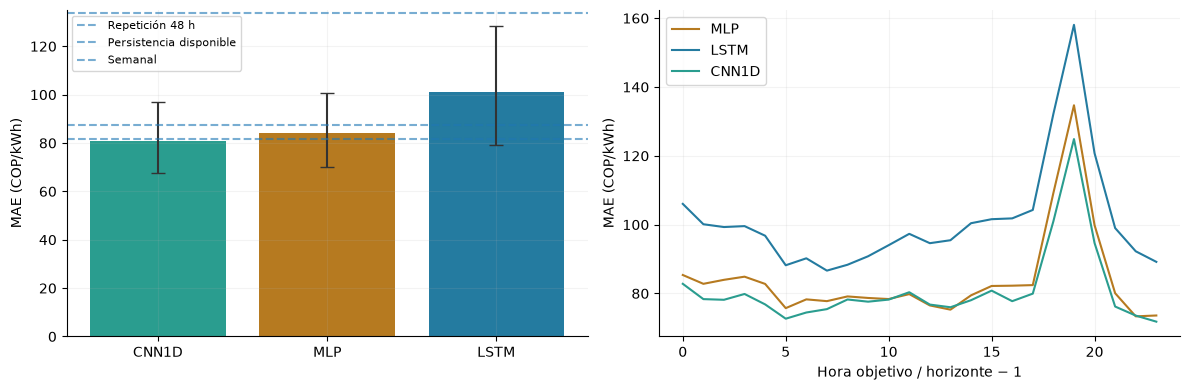

In [118]:
fe_plot(final_result, 'metricas_prueba', ROOT); plt.show()

**Interpretación.** El MAE de prueba ordena las configuraciones como CNN1D 81.01, MLP 84.01, LSTM 101.12 COP/kWh. La reducción de CNN1D frente a repetir 48 horas es 0.86 %. Las barras muestran IC temporales del 95 %. El mayor error medio entre familias aparece a las 19:00 y el menor a las 23:00; hora y horizonte coinciden.

### Comportamiento temporal

Las métricas por año distinguen la variación del error entre regímenes; su escala depende del nivel y dispersión del precio observado. El sesgo positivo corresponde a sobreestimación y el negativo a subestimación. El horizonte coincide con la hora objetivo porque todos los pronósticos comienzan a medianoche. El orden de los MAE es descriptivo; no constituye por sí solo un contraste entre familias.

In [119]:
display(final_tables['metrics_year'].query("model in ['MLP','LSTM','CNN1D']").round(4))
display(final_tables['metrics_horizon'].query("model in ['MLP','LSTM','CNN1D'] and horizon in [1,6,12,24]").round(4))

,model,year,origins,mae,rmse,mase,r2,bias
0,CNN1D,2022,365,35.425,59.327,1.2517,0.7807,-19.72
1,CNN1D,2023,365,91.671,127.86,3.2391,0.8203,-35.571
2,CNN1D,2024,366,132.39,251.6,4.6777,0.7123,-11.052
3,CNN1D,2025,365,64.421,118.1,2.2762,0.6005,-3.1965
4,LSTM,2022,365,36.05,58.61,1.2738,0.7865,-18.49
5,LSTM,2023,365,119.04,160.47,4.2061,0.7171,-64.882
6,LSTM,2024,366,176.54,353.06,6.2377,0.4335,-106.95
7,LSTM,2025,365,72.649,124.65,2.567,0.555,13.762
8,MLP,2022,365,38.103,61.088,1.3463,0.7675,-22.582
9,MLP,2023,365,94.611,133.39,3.343,0.8045,-29.164


,model,horizon,hour,mae,rmse,mase,r2,bias
0,CNN1D,1,0,82.798,166.3,2.9256,0.7842,-3.2855
5,CNN1D,6,5,72.658,137.27,2.5673,0.8193,-9.3975
11,CNN1D,12,11,80.352,154.31,2.8391,0.8166,4.9994
23,CNN1D,24,23,71.799,141.14,2.5369,0.8342,-20.346
24,LSTM,1,0,106.03,210.52,3.7465,0.6542,-27.004
29,LSTM,6,5,88.19,167.66,3.1161,0.7305,-25.044
35,LSTM,12,11,97.326,199.09,3.4389,0.6947,-25.994
47,LSTM,24,23,89.181,184.2,3.1511,0.7177,-42.83
48,MLP,1,0,85.363,168.16,3.0162,0.7793,-2.9533
53,MLP,6,5,75.728,144.69,2.6757,0.7989,-2.1824


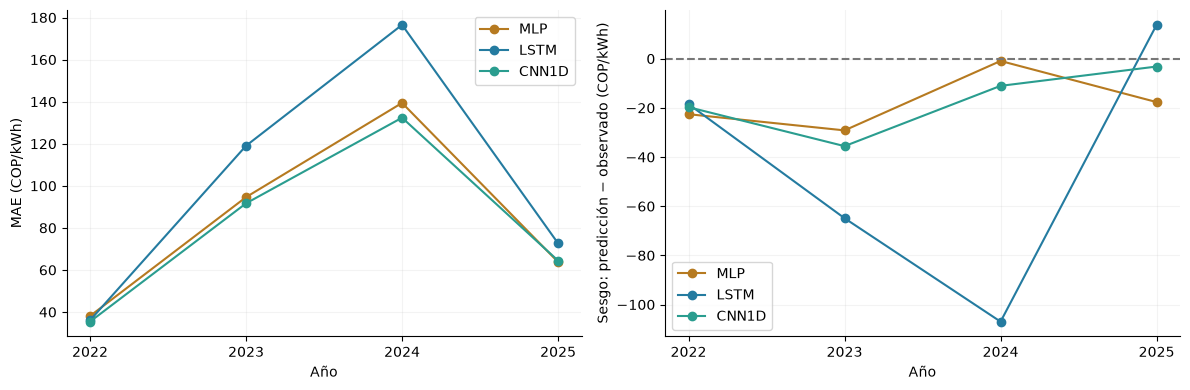

In [120]:
fe_plot(final_result, 'regimenes_prueba', ROOT); plt.show()

**Interpretación.** El MAE medio entre familias alcanza su máximo en 2024 y su mínimo en 2022. LSTM subestima especialmente en 2024 (sesgo −106,95 COP/kWh) y sobreestima en 2025 (+13,76); CNN1D y MLP mantienen sesgos anuales negativos. La variación anual muestra que el error global no resume por igual todos los regímenes de prueba.